### Phân tích chuẩn đoán

#### 1. Chuẩn bị dữ liệu

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

from scipy.stats import chi2_contingency, mannwhitneyu
from scipy.stats.contingency import association
import statsmodels.formula.api as smf
import statsmodels.api as sm

plt.rcParams.update({"font.family": "DejaVu Sans",
                     "axes.titlesize": 13, "figure.dpi": 120})

CLR = {"ngheo": "#C82333", "can": "#F8E71C",
       "sig": "#2EAF7D", "ns": "#AAAAAA"}

from pathlib import Path
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent


In [2]:
df = pd.read_excel(ROOT / "data" / "model" / "household_featured.xlsx")


In [3]:
# Biến mục tiêu: PHAN_LOAI_HO
df["Y"] = (df["PHAN_LOAI_HO"] == "Hộ nghèo").astype(int)

# Xử lý thiếu GIOI_TINH_CHU_HO
# Không impute bằng mode để tránh làm sai lệch phân bố giới tính.
# Các hộ thiếu được giữ lại bằng nhóm riêng "Không rõ".
missing_gender_before = (
    df["GIOI_TINH_CHU_HO"]
    .replace(["", "nan", "NaN", "None"], np.nan)
    .isna()
    .sum()
)

df["GIOI_TINH_CHU_HO"] = (
    df["GIOI_TINH_CHU_HO"]
    .replace(["", "nan", "NaN", "None"], np.nan)
    .fillna("Không rõ")
)

# Thứ tự nhóm tuổi
AGE_ORDER = ["<35", "35-49", "50-64", "65+"]
df["NHOM_TUOI_CHU_HO"] = pd.Categorical(
    df["NHOM_TUOI_CHU_HO"], categories=AGE_ORDER, ordered=True)

# Gộp dân tộc: top 5 + Khác
TOP5_DT = df["DAN_TOC_CHU_HO"].value_counts().head(5).index.tolist()
df["DAN_TOC_GRP"] = df["DAN_TOC_CHU_HO"].where(
    df["DAN_TOC_CHU_HO"].isin(TOP5_DT), "Khác")

print(f"Tổng hộ: {len(df):,}  |  Hộ nghèo: {df['Y'].sum():,}  |  Hộ cận nghèo: {(df['Y']==0).sum():,}")
print(f"Tỉ lệ Hộ nghèo (base rate): {df['Y'].mean()*100:.1f}%")
print(f"GIOI_TINH_CHU_HO thiếu được gán 'Không rõ': {missing_gender_before:,} hộ ({missing_gender_before/len(df)*100:.2f}%)")
df.head(5)


Tổng hộ: 26,953  |  Hộ nghèo: 14,079  |  Hộ cận nghèo: 12,874
Tỉ lệ Hộ nghèo (base rate): 52.2%
GIOI_TINH_CHU_HO thiếu được gán 'Không rõ': 7,180 hộ (26.64%)


,HOUSEHOLD_ID,STT_HO,HUYEN,XA,PHAN_LOAI_HO,NHAN_KHAU,NHAN_KHAU_GOC_MAX,SO_CHU_HO,SO_XA_TRONG_HO,SO_HUYEN_TRONG_HO,...,TUOI_CHU_HO,GIOI_TINH_CHU_HO,DAN_TOC_CHU_HO,NHOM_TUOI_CHU_HO,TUOI_TRUNG_BINH_HO,TUOI_LON_NHAT,TUOI_NHO_NHAT,DO_LECH_TUOI,Y,DAN_TOC_GRP
0,1,1,Huyện Cư Jút,TÂM THẮNG,Hộ nghèo,1,1.0,1,1,1,...,87.0,Nữ,Kinh,65+,87.000000,87.0,87.0,0.0,1,Kinh
1,2,2,Huyện Cư Jút,TÂM THẮNG,Hộ nghèo,4,4.0,1,1,1,...,46.0,Nam,Kinh,35-49,29.750000,46.0,13.0,33.0,1,Kinh
2,3,3,Huyện Cư Jút,TÂM THẮNG,Hộ nghèo,2,2.0,1,1,1,...,66.0,Nam,Kinh,65+,60.500000,66.0,55.0,11.0,1,Kinh
3,4,4,Huyện Cư Jút,TÂM THẮNG,Hộ nghèo,1,1.0,1,1,1,...,80.0,Nữ,Kinh,65+,80.000000,80.0,80.0,0.0,1,Kinh
4,5,5,Huyện Cư Jút,TÂM THẮNG,Hộ nghèo,6,6.0,1,1,1,...,66.0,Nam,Kinh,65+,33.333333,66.0,10.0,56.0,1,Kinh


**Ghi chú xử lý missing `GIOI_TINH_CHU_HO`:**
Có 7,180 hộ, tương đương 26.64%, thiếu thông tin `GIOI_TINH_CHU_HO` và được gán vào nhóm `"Không rõ"`. Nhóm này không đại diện cho một giới tính thực tế mà phản ánh thiếu thông tin chủ hộ trong dữ liệu. Vì tỷ lệ missing khá lớn, các kết quả liên quan đến `GIOI_TINH_CHU_HO` cần được diễn giải thận trọng.


#### Đánh giá Độ tin cậy Dữ liệu Tuổi
**Mục tiêu:** Đánh giá độ tin cậy của trường NGAY_SINH trước khi sử dụng để xây dựng các biến:
TUOI,
NHOM_TUOI,
SO_U50,
TY_LE_U50,
...

In [4]:
import re

df_raw = pd.read_excel(ROOT / "data" / "clean" / "Chuan_hoa_Toan_Tinh.xlsx", dtype=str)
df_raw = df_raw[df_raw["PHAN_LOAI_HO"].isin(["Hộ nghèo", "Hộ cận nghèo"])].copy()

def parse_year(s):
    if pd.isna(s):
        return np.nan
    s = str(s).strip()
    m = re.match(r"^(\d{1,2})-(\d{1,2})-(\d{4})$", s)
    if m:
        return int(m.group(3))
    if m:
        return int(m.group(1))
    return np.nan
df_raw["NAM_SINH"] = df_raw["NGAY_SINH"].apply(parse_year)
df_raw["TUOI"] = 2026- df_raw["NAM_SINH"]
print(f"Tổng bản ghi (2 nhãn): {len(df_raw):,}")
print(f"Có NGAY_SINH: {df_raw['NGAY_SINH'].notna().sum():,}")
print(f"Thiếu NGAY_SINH: {df_raw['NGAY_SINH'].isna().sum():,} ({df_raw['NGAY_SINH'].isna().mean()*100:.2f}%)")


Tổng bản ghi (2 nhãn): 98,478
Có NGAY_SINH: 96,676
Thiếu NGAY_SINH: 1,802 (1.83%)


#### Thiếu dữ liệu ngày sinh phân bố như thế nào theo địa bàn?

In [5]:
miss_h = df_raw["NGAY_SINH"].isna().groupby(df_raw["HUYEN"]).sum()
total_h = df_raw.groupby("HUYEN").size()
miss_q = df_raw["NGAY_SINH"].isna().groupby(df_raw["QUANHE_CHUHO"]).sum()
total_q = df_raw.groupby("QUANHE_CHUHO").size()

miss_huyen = pd.DataFrame({
    "N_thiếu": miss_h,
    "Tổng": total_h,
    "% Thiếu": (miss_h / total_h *100).round(2)
}).sort_values("% Thiếu", ascending=False)

miss_quanhe = pd.DataFrame({
    "N_thiếu": miss_q,
    "Tổng": total_q,
    "% Thiếu": (miss_q / total_q *100).round(2)
}).sort_values("% Thiếu", ascending=False)

print("Thiếu NGAY_SINH theo HUYEN:")
display(miss_huyen)
print()
print("Thiếu NGAY_SINH theo QUANHE_CHUHO:")
display(miss_quanhe)
print()
n_miss_chuho = df_raw[(df_raw["QUANHE_CHUHO"]=="Chủ hộ") & (df_raw["NGAY_SINH"].isna())]
print(f"Chủ hộ thiếu NGAY_SINH: {len(n_miss_chuho):,} ({len(n_miss_chuho)/df_raw[df_raw['QUANHE_CHUHO']=='Chủ hộ'].shape[0]*100:.2f}%)")
print(f"→ Ảnh hưởng trực tiếp {len(n_miss_chuho):,} hộ không tính được TUOI_CHU_HO")

Thiếu NGAY_SINH theo HUYEN:


,N_thiếu,Tổng,% Thiếu
HUYEN,,,
Huyện Krông Nô,1137,14838,7.66
Thành phố Gia Nghĩa,27,957,2.82
Huyện Đắk Mil,67,2738,2.45
Huyện Đắk R'lấp,51,4228,1.21
Huyện Cư Jút,125,11767,1.06
Huyện Đắk Song,69,8981,0.77
Huyện Đắk Glong,197,32908,0.60
Huyện Tuy Đức,129,22061,0.58



Thiếu NGAY_SINH theo QUANHE_CHUHO:


,N_thiếu,Tổng,% Thiếu
QUANHE_CHUHO,,,
Khác,707,714,99.02
Cha/mẹ,23,1555,1.48
Chủ hộ,267,20306,1.31
Con (Khác họ),169,15201,1.11
Cháu,44,4031,1.09
Vợ/chồng,166,15628,1.06
Con,388,37926,1.02
Cháu (Khác họ),29,2942,0.99



Chủ hộ thiếu NGAY_SINH: 267 (1.31%)
→ Ảnh hưởng trực tiếp 267 hộ không tính được TUOI_CHU_HO


#### Các trường hợp trùng định danh có thể gây sai lệch tuổi như thế nào?

In [6]:
# Trùng định danh cấp thành viên: cùng STT_HO + HO_TEN_THANH_VIEN + NGAY_SINH
dup_member = df_raw[df_raw.duplicated(
    subset=["STT_HO","HO_TEN_THANH_VIEN","NGAY_SINH"], keep=False)].copy()

# Trùng định danh cấp hộ: cùng HO_TEN_CHU_HO + XA (trong cùng địa bàn)
dup_ho = df_raw[df_raw.duplicated(
    subset=["HO_TEN_CHU_HO","XA"], keep=False)].copy()

# Thống kê tác động lên TUOI
dup_member_tuoi_ok  = dup_member["TUOI"].notna().sum()
dup_member_tuoi_null= dup_member["TUOI"].isna().sum()

print("=== Trùng định danh cấp Thành viên ===")
print(f"Bản ghi trùng (cùng STT_HO + Tên + Ngày sinh): {len(dup_member):,}")
print(f"  Có TUOI hợp lệ : {dup_member_tuoi_ok:,}")
print(f"  Thiếu TUOI     : {dup_member_tuoi_null:,}")
print()
print("Phân bố theo Huyện:")
dm_h = dup_member.groupby("HUYEN").size().sort_values(ascending=False)
print(dm_h.to_string)
print()

print("=== Trùng định danh cấp Hộ (HO_TEN_CHU_HO × XA) ===")
print(f"Bản ghi trong hộ trùng tên chủ hộ cùng xã: {len(dup_ho):,}")
print(f"Số tên chủ hộ unique bị trùng: {dup_ho['HO_TEN_CHU_HO'].nunique():,}")
print()
print("Phân bố theo Huyện:")
dh_h = dup_ho.groupby("HUYEN").size().sort_values(ascending=False)
print(dh_h.to_string)
print()

# Ví dụ cụ thể: cùng tên chủ hộ + xã nhưng TUOI khác
sample_dup = (df_raw[df_raw.duplicated(subset=["HO_TEN_CHU_HO","XA"], keep=False)]
              .groupby(["HO_TEN_CHU_HO","XA"])
              .agg(N=("STT_HO","count"),
                   TUOI_min=("TUOI","min"),
                   TUOI_max=("TUOI","max"))
              .assign(DELTA_TUOI=lambda x: x["TUOI_max"] - x["TUOI_min"])
              .query("DELTA_TUOI > 0")
              .sort_values("DELTA_TUOI", ascending=False))
print(f"Trong đó tên chủ hộ × xã có TUOI khác nhau (hộ thực sự khác):")
print(f"  {len(sample_dup):,} nhóm")
if len(sample_dup):
    print(sample_dup.head(8).to_string())


=== Trùng định danh cấp Thành viên ===
Bản ghi trùng (cùng STT_HO + Tên + Ngày sinh): 107
  Có TUOI hợp lệ : 97
  Thiếu TUOI     : 10

Phân bố theo Huyện:
<bound method Series.to_string of HUYEN
Huyện Krông Nô     89
Huyện Đắk Glong    12
Huyện Tuy Đức       6
dtype: int64>

=== Trùng định danh cấp Hộ (HO_TEN_CHU_HO × XA) ===
Bản ghi trong hộ trùng tên chủ hộ cùng xã: 96,212
Số tên chủ hộ unique bị trùng: 15,926

Phân bố theo Huyện:
<bound method Series.to_string of HUYEN
Huyện Đắk Glong        32700
Huyện Tuy Đức          21907
Huyện Krông Nô         14673
Huyện Cư Jút           11615
Huyện Đắk Song          7596
Huyện Đắk R'lấp         4103
Huyện Đắk Mil           2697
Thành phố Gia Nghĩa      921
dtype: int64>

Trong đó tên chủ hộ × xã có TUOI khác nhau (hộ thực sự khác):
  18,306 nhóm
                            N  TUOI_min  TUOI_max  DELTA_TUOI
HO_TEN_CHU_HO   XA                                           
MÙA A LẦU       ĐẮK SOM     7    -987.0      43.0      1030.0
NGUYỄN VĂN HIỆ

#### Lỗi định dạng ngày sinh ảnh hưởng thế nào đến tính tuổi?

In [7]:
# Phân loại lỗi
df_raw["LOI_SERIAL"]   = ((df_raw["NAM_SINH"] < 1914) |
                           (df_raw["TUOI"]     > 110)).astype(int)
df_raw["LOI_TUONGLAI"] = (df_raw["NAM_SINH"] > 2026).astype(int)
df_raw["LOI_MISSING"]  = df_raw["NGAY_SINH"].isna().astype(int)

serial   = df_raw[df_raw["LOI_SERIAL"]   == 1].copy()
tuonglai = df_raw[df_raw["LOI_TUONGLAI"] == 1].copy()

print("=== Lỗi định dạng NGAY_SINH ===")
print(f"[Loại 1] Serial Excel (năm sinh < 1914 / tuổi > 110): {len(serial):,} bản ghi")
print(f"[Loại 2] Năm sinh tương lai (> 2026)               : {len(tuonglai):,} bản ghi")
print(f"[Loại 3] Thiếu hoàn toàn                           : {df_raw['LOI_MISSING'].sum():,} bản ghi")
print()
print("Chi tiết Loại 1 – Serial Excel:")
print(serial[["STT_HO","HO_TEN_THANH_VIEN","NGAY_SINH","NAM_SINH","TUOI","QUANHE_CHUHO","HUYEN"]]
      .sort_values("NAM_SINH").to_string())
print()
print("Chi tiết Loại 2 – Năm sinh tương lai:")
print(tuonglai[["STT_HO","HO_TEN_THANH_VIEN","NGAY_SINH","NAM_SINH","TUOI","QUANHE_CHUHO","HUYEN"]].to_string())
print()
print("Tổng hợp lỗi định dạng theo Huyện:")
err_sum = df_raw.groupby("HUYEN")[["LOI_SERIAL","LOI_TUONGLAI","LOI_MISSING"]].sum()
err_sum["TONG_BAN_GHI"] = df_raw.groupby("HUYEN").size()
err_sum["TONG_LOI"]     = err_sum["LOI_SERIAL"] + err_sum["LOI_TUONGLAI"] + err_sum["LOI_MISSING"]
err_sum["PCT_LOI"]      = (err_sum["TONG_LOI"] / err_sum["TONG_BAN_GHI"] * 100).round(2)
err_sum = err_sum.sort_values("PCT_LOI", ascending=False)
err_sum.columns = ["Serial Excel","Tương lai","Thiếu","Tổng bản ghi","Tổng lỗi","% lỗi"]
print(err_sum.to_string())


=== Lỗi định dạng NGAY_SINH ===
[Loại 1] Serial Excel (năm sinh < 1914 / tuổi > 110): 74 bản ghi
[Loại 2] Năm sinh tương lai (> 2026)               : 4 bản ghi
[Loại 3] Thiếu hoàn toàn                           : 1,802 bản ghi

Chi tiết Loại 1 – Serial Excel:
      STT_HO      HO_TEN_THANH_VIEN   NGAY_SINH  NAM_SINH    TUOI    QUANHE_CHUHO            HUYEN
37601   7646           ĐỖ THỊ THANH  01-06-0984     984.0  1042.0        Vợ/chồng  Huyện Đắk Glong
39969   8171  ĐINH NGUYỄN NGỌC LINH  23-10-1006    1006.0  1020.0             Con  Huyện Đắk Glong
39762   8128            LÊ THỊ HẠNH  01-01-1009    1009.0  1017.0        Vợ/chồng  Huyện Đắk Glong
76699  16981   PHẠM NGHIÊM KHÁNH VY  18-09-1017    1017.0  1009.0             Con    Huyện Tuy Đức
10479   2330              MA VĂN SO  10-05-1039    1039.0   987.0          Cha/mẹ     Huyện Cư Jút
78558  17543        NGUYỄN THỊ HOÀI  04-10-1081    1081.0   945.0        Vợ/chồng    Huyện Tuy Đức
47113   9881       HOÀNG THỊ NGHIỆP  01-10-1083

#### 2. Phân tích chuẩn đoán

#### 2.1. Kiểm định Liên hệ Thống kê
**Mục tiêu**: Xác định biến phân loại nào có mối liên hệ có ý nghĩa
với PHAN_LOAI_HO và đo lường độ mạnh của liên hệ đó.
- Các biến NHOM_TUOI, DAN_TOC, GIOI_TINH, HUYEN có liên hệ thống kê
  với phân loại hộ nghèo/cận nghèo không, và liên hệ đó mạnh đến đâu?
  (Chi-Square + Cramér's V)
- Tỉ lệ Hộ nghèo phân bố cụ thể thế nào theo từng dân tộc và nhóm tuổi?
  (Crosstab + Bar Chart)

#### Các biến NHOM_TUOI, DAN_TOC, GIOI_TINH, HUYEN có liên hệ thống kê với phân loại hộ nghèo/cận nghèo không, và liên hệ đó mạnh đến đâu?

In [8]:
cat_vars = {
    "NHOM_TUOI_CHU_HO" : "Nhóm tuổi Chủ hộ",
    "DAN_TOC_GRP"       : "Dân tộc Chủ hộ",
    "GIOI_TINH_CHU_HO"  : "Giới tính Chủ hộ",
    "HUYEN"             : "Huyện / TP",
}

results = []
for col, label in cat_vars.items():
    sub = df.dropna(subset=[col])
    ct  = pd.crosstab(sub[col], sub["PHAN_LOAI_HO"])
    chi2, p, dof, _ = chi2_contingency(ct)
    v = association(ct, method="cramer")
    sig = "***" if p < 0.001 else ("**" if p < 0.01 else ("*" if p < 0.05 else "ns"))
    results.append({"Biến": label, "Chi²": round(chi2,2),
                    "df": dof, "p-value": f"{p:.2e}",
                    "Cramér's V": round(v,4), "Sig.": sig})

cramers_df = pd.DataFrame(results).sort_values("Cramér's V", ascending=False)
print("Kết quả kiểm định Chi-Square + Cramér's V:")
print(cramers_df.to_string(index=False))
print()
print("Diễn giải Cramér's V:  V<0.10 = yếu  |  0.10–0.30 = trung bình  |  >0.30 = mạnh")


Kết quả kiểm định Chi-Square + Cramér's V:
            Biến    Chi²  df  p-value  Cramér's V Sig.
      Huyện / TP 2515.69   7 0.00e+00      0.3055  ***
  Dân tộc Chủ hộ 1520.57   4 0.00e+00      0.2375  ***
Nhóm tuổi Chủ hộ   69.71   3 4.92e-15      0.0590  ***
Giới tính Chủ hộ    0.72   2 6.96e-01      0.0052   ns

Diễn giải Cramér's V:  V<0.10 = yếu  |  0.10–0.30 = trung bình  |  >0.30 = mạnh


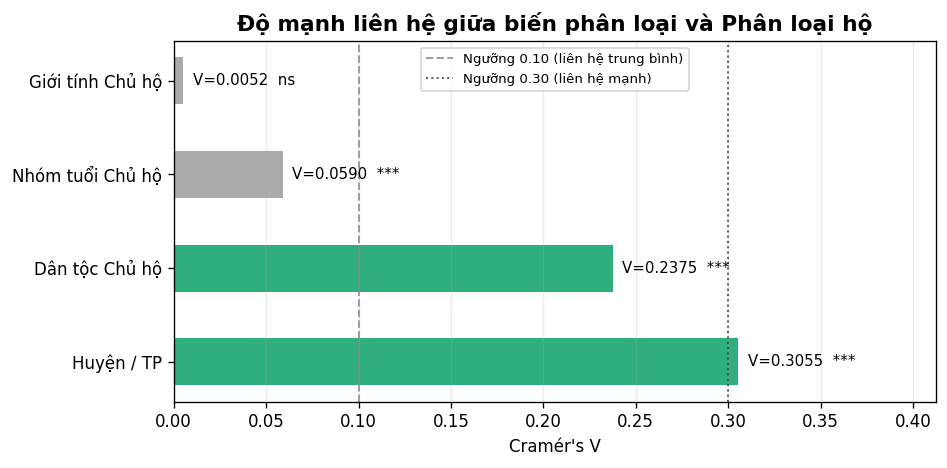

In [9]:
# ── Biểu đồ ──
fig, ax = plt.subplots(figsize=(8, 4))
colors = [CLR["sig"] if float(r["Cramér's V"]) >= 0.10 else CLR["ns"]
          for _, r in cramers_df.iterrows()]
bars = ax.barh(cramers_df["Biến"], cramers_df["Cramér's V"],
               color=colors, height=0.5, edgecolor="none")
ax.axvline(0.10, color="#888", lw=1.2, ls="--", alpha=0.8, label="Ngưỡng 0.10 (liên hệ trung bình)")
ax.axvline(0.30, color="#333", lw=1.2, ls=":",  alpha=0.8, label="Ngưỡng 0.30 (liên hệ mạnh)")
for bar, (_, row) in zip(bars, cramers_df.iterrows()):
    ax.text(bar.get_width() + 0.005, bar.get_y() + bar.get_height()/2,
            f"V={row["Cramér's V"]:.4f}  {row['Sig.']}",
            va="center", fontsize=9)
ax.set_xlim(0, cramers_df["Cramér's V"].max() * 1.35)
ax.set_xlabel("Cramér's V")
ax.set_title("Độ mạnh liên hệ giữa biến phân loại và Phân loại hộ", fontweight="bold")
ax.legend(fontsize=8); ax.grid(axis="x", alpha=0.25)
plt.tight_layout(); plt.show()


**Nhận xét:**
- **HUYEN** có Cramér's V cao nhất (~0.30) → liên hệ **mạnh** với phân loại hộ: địa bàn là yếu tố phân hóa nghèo rõ nhất.
- **DAN_TOC_GRP** đứng thứ hai (~0.23) → liên hệ **trung bình đến mạnh**: thành phần dân tộc phân hóa rõ rệt tỉ lệ nghèo.
- **NHOM_TUOI_CHU_HO** có V~0.05 → liên hệ **yếu** nhưng có ý nghĩa thống kê.
- **GIOI_TINH_CHU_HO** không có ý nghĩa thống kê (p=0.696, V~0.005) → giới tính chủ hộ không phân biệt rõ nghèo/cận nghèo trong kiểm định Chi-square.

**Insight:**
- Chi-Square chỉ nói "có liên hệ hay không" – Cramér's V mới nói "liên hệ mạnh đến đâu".
- Kết quả này định hướng cho Logistic Regression: ưu tiên đưa HUYEN và DAN_TOC vào model; GIOI_TINH có thể giữ như biến kiểm soát nhưng không phải trục phân hóa chính.
- V nhỏ không có nghĩa là biến không quan trọng – cần hồi quy để kiểm soát confounders.


#### Tỉ lệ Hộ nghèo phân bố cụ thể thế nào theo từng dân tộc và nhóm tuổi?

In [10]:
ct_dt = pd.crosstab(df["DAN_TOC_GRP"], df["PHAN_LOAI_HO"])
ct_dt["Tổng"]    = ct_dt.sum(axis=1)
ct_dt["% Nghèo"] = (ct_dt["Hộ nghèo"] / ct_dt["Tổng"] * 100).round(1)
ct_dt = ct_dt.sort_values("% Nghèo", ascending=False)
print("Crosstab: Dân tộc × Phân loại hộ")
print(ct_dt.to_string())

Crosstab: Dân tộc × Phân loại hộ
PHAN_LOAI_HO  Hộ cận nghèo  Hộ nghèo   Tổng  % Nghèo
DAN_TOC_GRP                                         
Dao                    658      2924   3582     81.6
Ê-đê                   521       577   1098     52.6
Khác                  5910      5892  11802     49.9
M'Nông                2133      1928   4061     47.5
Kinh                  3652      2758   6410     43.0


In [11]:
# ── Số liệu: Nhóm tuổi ──
ct_tuoi = pd.crosstab(df["NHOM_TUOI_CHU_HO"], df["PHAN_LOAI_HO"])
ct_tuoi["Tổng"]    = ct_tuoi.sum(axis=1)
ct_tuoi["% Nghèo"] = (ct_tuoi["Hộ nghèo"] / ct_tuoi["Tổng"] * 100).round(1)
print("Crosstab: Nhóm tuổi Chủ hộ × Phân loại hộ")
print(ct_tuoi.to_string())

Crosstab: Nhóm tuổi Chủ hộ × Phân loại hộ
PHAN_LOAI_HO      Hộ cận nghèo  Hộ nghèo  Tổng  % Nghèo
NHOM_TUOI_CHU_HO                                       
<35                       1222      1637  2859     57.3
35-49                     4537      4688  9225     50.8
50-64                     2463      2292  4755     48.2
65+                       1460      1730  3190     54.2


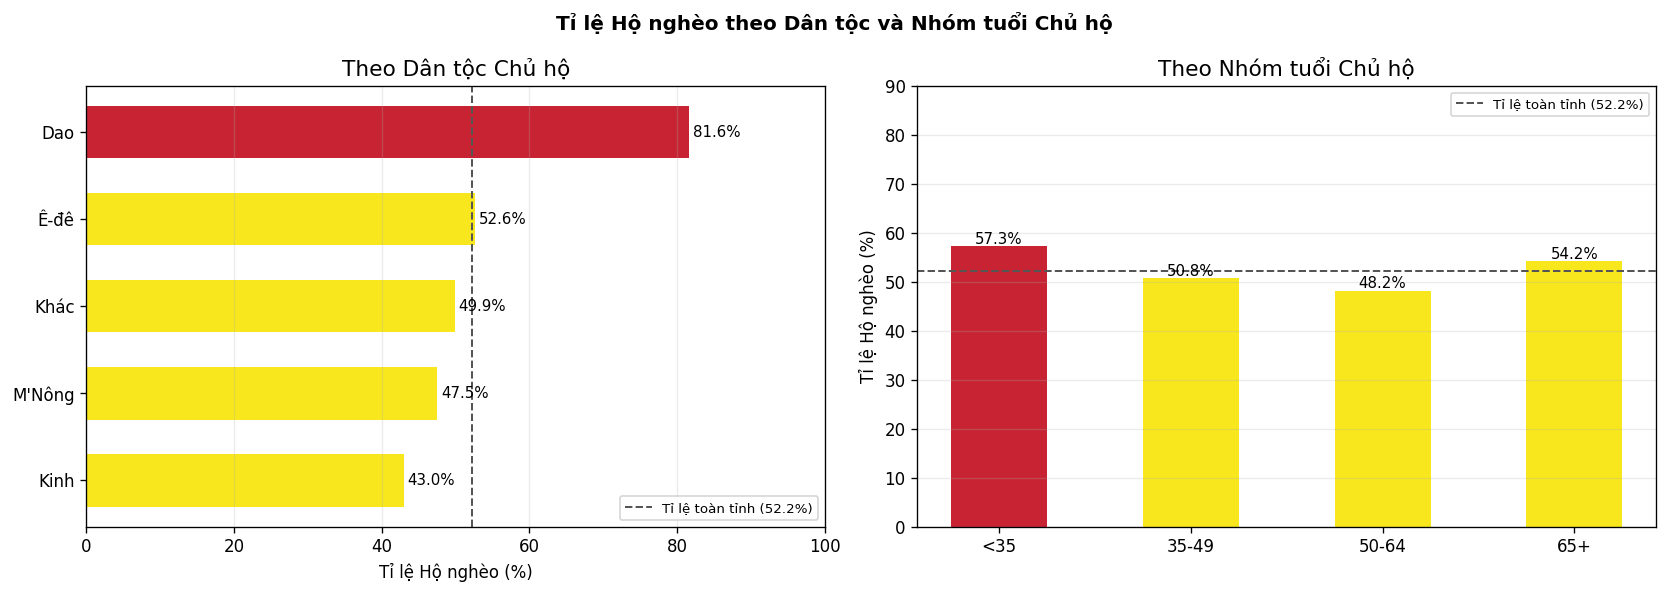

In [12]:
# ── Biểu đồ ──
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Tỉ lệ Hộ nghèo theo Dân tộc và Nhóm tuổi Chủ hộ", fontweight="bold")

# Trái: Dân tộc
pct_dt = ct_dt["% Nghèo"].sort_values(ascending=True)
colors_dt = [CLR["ngheo"] if v >= 55 else CLR["can"] for v in pct_dt]
axes[0].barh(pct_dt.index, pct_dt.values, color=colors_dt, height=0.6, edgecolor="none")
axes[0].axvline(df["Y"].mean()*100, color="#555", lw=1.2, ls="--",
                label=f"Tỉ lệ toàn tỉnh ({df['Y'].mean()*100:.1f}%)")
for i, (idx, val) in enumerate(pct_dt.items()):
    axes[0].text(val+0.5, i, f"{val:.1f}%", va="center", fontsize=9)
axes[0].set_xlabel("Tỉ lệ Hộ nghèo (%)")
axes[0].set_xlim(0, 100)
axes[0].set_title("Theo Dân tộc Chủ hộ")
axes[0].legend(fontsize=8); axes[0].grid(axis="x", alpha=0.25)

# Phải: Nhóm tuổi
pct_tuoi = ct_tuoi["% Nghèo"]
colors_t  = [CLR["ngheo"] if v >= 55 else CLR["can"] for v in pct_tuoi]
axes[1].bar(pct_tuoi.index.astype(str), pct_tuoi.values,
            color=colors_t, edgecolor="none", width=0.5)
axes[1].axhline(df["Y"].mean()*100, color="#555", lw=1.2, ls="--",
                label=f"Tỉ lệ toàn tỉnh ({df['Y'].mean()*100:.1f}%)")
for i, val in enumerate(pct_tuoi.values):
    axes[1].text(i, val+0.5, f"{val:.1f}%", ha="center", fontsize=9)
axes[1].set_ylabel("Tỉ lệ Hộ nghèo (%)")
axes[1].set_ylim(0, 90)
axes[1].set_title("Theo Nhóm tuổi Chủ hộ")
axes[1].legend(fontsize=8); axes[1].grid(axis="y", alpha=0.25)

plt.tight_layout(); plt.show()


**Nhận xét:**
- **Dao** có tỉ lệ Hộ nghèo cao nhất (~81%) – cách tỉ lệ toàn tỉnh (~52%) tới 29 điểm phần trăm.
- **Kinh** có tỉ lệ thấp nhất trong nhóm dân tộc thiểu số (~43%) – thấp hơn cả tỉ lệ chung.
- **Nhóm tuổi <35** có tỉ lệ nghèo cao nhất (57%) trong khi **50-64** thấp nhất (48%).
- Mô hình chữ U ngược theo tuổi: rất trẻ và rất già đều dễ nghèo hơn nhóm trung niên.

**Insight:**
- Dao là dân tộc di cư, thiếu đất canh tác truyền thống → rủi ro nghèo cấu trúc cao nhất.
- Ê-đê là dân tộc tại chỗ có đất rẫy truyền thống → đệm tốt hơn so với dân tộc di cư.
- Chủ hộ <35 nghèo cao = thiếu tích lũy + gánh con nhỏ; chủ hộ 65+ nghèo cao = mất sức lao động.

#### 2.2. Định lượng Mức liên hệ có điều kiện
**Mục tiêu**: Ước lượng mức liên hệ giữa từng yếu tố và xác suất hộ thuộc nhóm nghèo sau khi kiểm soát các biến còn lại, đồng thời đánh giá sức giải thích của mô hình.

- Khi kiểm soát đồng thời dân tộc, địa bàn, giới tính và tuổi, yếu tố nào có odds nghèo cao hơn/thấp hơn nhóm tham chiếu? (Logistic Regression Model A - Categorical)
- Mỗi nhóm có odds nghèo cao hơn/thấp hơn nhóm tham chiếu bao nhiêu lần? (Odds Ratio + Forest Plot)
- Việc bổ sung thêm các biến cấu trúc hộ như tuổi chủ hộ, nhân khẩu, tỉ lệ lao động có cải thiện đáng kể sức giải thích của mô hình không? (Logistic Regression Model B - Categorical + Numeric)
- Model A và Model B giải thích được bao nhiêu phần thông tin so với null model, và nhóm biến nào đóng góp nhiều nhất? (So sánh McFadden Pseudo R²)

**Lưu ý diễn giải:** Logistic regression trong notebook này dùng dữ liệu cắt ngang, vì vậy kết quả nên được hiểu là **liên hệ có điều kiện**, không phải bằng chứng nhân quả.


#### Khi kiểm soát đồng thời dân tộc, địa bàn, giới tính và tuổi thì yếu tố nào thực sự làm tăng/giảm xác suất là Hộ nghèo ? 

In [13]:
df_a = df.dropna(subset=["NHOM_TUOI_CHU_HO","DAN_TOC_GRP","GIOI_TINH_CHU_HO","HUYEN"])

formula_a = ("Y ~ C(NHOM_TUOI_CHU_HO, Treatment('<35'))"
             " + C(DAN_TOC_GRP, Treatment('Kinh'))"
             " + C(GIOI_TINH_CHU_HO, Treatment('Nam'))"
             " + C(HUYEN, Treatment('Huyện Cư Jút'))")

model_a = smf.logit(formula_a, data=df_a).fit(disp=0)

coef_a = model_a.summary2().tables[1].copy()
coef_a.columns = ["β","SE","z","p","CI_low","CI_high"]
coef_a = coef_a.round(4)

print(f"Model A – Số quan sát: {int(model_a.nobs):,}")
print(f"Log-Likelihood: {model_a.llf:.2f}")
print(f"McFadden Pseudo R²: {model_a.prsquared:.4f}")
print(f"AIC: {model_a.aic:.2f}  |  BIC: {model_a.bic:.2f}")
print()
print("Bảng hệ số hồi quy logistic (Model A):")
print(coef_a[["β","SE","z","p","CI_low","CI_high"]].to_string())


Model A – Số quan sát: 20,029
Log-Likelihood: -12199.89
McFadden Pseudo R²: 0.1205
AIC: 24433.78  |  BIC: 24568.17

Bảng hệ số hồi quy logistic (Model A):
                                                                 β      SE        z       p  CI_low  CI_high
Intercept                                                  -0.3955  0.0692  -5.7131  0.0000 -0.5311  -0.2598
C(NHOM_TUOI_CHU_HO, Treatment('<35'))[T.35-49]             -0.0728  0.0486  -1.4971  0.1344 -0.1681   0.0225
C(NHOM_TUOI_CHU_HO, Treatment('<35'))[T.50-64]             -0.1715  0.0537  -3.1956  0.0014 -0.2766  -0.0663
C(NHOM_TUOI_CHU_HO, Treatment('<35'))[T.65+]                0.1988  0.0588   3.3820  0.0007  0.0836   0.3141
C(DAN_TOC_GRP, Treatment('Kinh'))[T.Dao]                    1.3606  0.0565  24.0663  0.0000  1.2498   1.4714
C(DAN_TOC_GRP, Treatment('Kinh'))[T.Khác]                   0.1703  0.0429   3.9681  0.0001  0.0862   0.2544
C(DAN_TOC_GRP, Treatment('Kinh'))[T.M'Nông]                 0.1356  0.0437   3.100

In [14]:
model_a = smf.logit(
    formula_a,
    data=df_a
).fit()

Optimization terminated successfully.
         Current function value: 0.609111
         Iterations 6


In [15]:
coef_a = model_a.summary2().tables[1]
display(coef_a)
coef_a.columns = ["β", "SE", "z", "p", "CI_low", "CI_high"]

,Coef.,Std.Err.,z,P>|z|,[0.025,0.975]
Intercept,-0.395452,0.069218,-5.713099,1.109368e-08,-0.531118,-0.259786
"C(NHOM_TUOI_CHU_HO, Treatment('<35'))[T.35-49]",-0.072799,0.048628,-1.497058,1.343781e-01,-0.168109,0.022510
"C(NHOM_TUOI_CHU_HO, Treatment('<35'))[T.50-64]",-0.171474,0.053660,-3.195582,1.395493e-03,-0.276644,-0.066303
"C(NHOM_TUOI_CHU_HO, Treatment('<35'))[T.65+]",0.198848,0.058795,3.382037,7.195054e-04,0.083611,0.314085
"C(DAN_TOC_GRP, Treatment('Kinh'))[T.Dao]",1.360577,0.056535,24.066281,5.638567e-128,1.249771,1.471382
"C(DAN_TOC_GRP, Treatment('Kinh'))[T.Khác]",0.170268,0.042910,3.968058,7.246065e-05,0.086166,0.254369
"C(DAN_TOC_GRP, Treatment('Kinh'))[T.M'Nông]",0.135589,0.043725,3.100946,1.929033e-03,0.049889,0.221288
"C(DAN_TOC_GRP, Treatment('Kinh'))[T.Ê-đê]",-0.407745,0.074934,-5.441428,5.285524e-08,-0.554612,-0.260878
"C(GIOI_TINH_CHU_HO, Treatment('Nam'))[T.Không rõ]",-0.756044,0.108522,-6.966712,3.244342e-12,-0.968744,-0.543344
"C(GIOI_TINH_CHU_HO, Treatment('Nam'))[T.Nữ]",0.314667,0.036304,8.667593,4.413527e-18,0.243513,0.385821


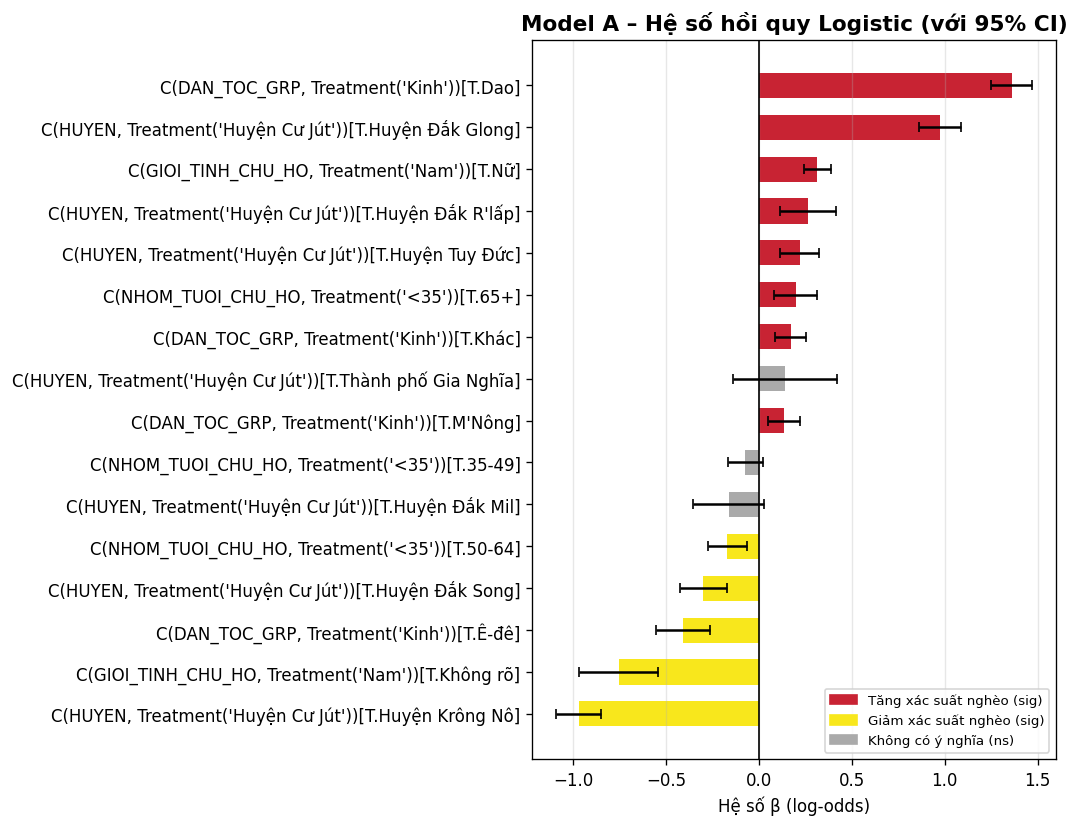

In [16]:
# ── Biểu đồ: coefficient plot ──
df_plot = coef_a.iloc[1:].copy()   # bỏ Intercept
df_plot["sig"] = df_plot["p"] < 0.05
df_plot = df_plot.sort_values("β")

colors_c = [CLR["ngheo"] if (row["sig"] and row["β"]>0)
            else CLR["can"] if (row["sig"] and row["β"]<0)
            else CLR["ns"] for _, row in df_plot.iterrows()]

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(df_plot.index, df_plot["β"], xerr=[df_plot["β"]-df_plot["CI_low"],
                                            df_plot["CI_high"]-df_plot["β"]],
        color=colors_c, height=0.6, capsize=3, edgecolor="none")
ax.axvline(0, color="black", lw=1)
ax.set_xlabel("Hệ số β (log-odds)")
ax.set_title("Model A – Hệ số hồi quy Logistic (với 95% CI)", fontweight="bold")
legend_h = [plt.Rectangle((0,0),1,1, color=CLR["ngheo"], label="Tăng xác suất nghèo (sig)"),
            plt.Rectangle((0,0),1,1, color=CLR["can"],   label="Giảm xác suất nghèo (sig)"),
            plt.Rectangle((0,0),1,1, color=CLR["ns"],    label="Không có ý nghĩa (ns)")]
ax.legend(handles=legend_h, fontsize=8)
ax.grid(axis="x", alpha=0.3)
plt.tight_layout(); plt.show()


**Nhận xét:**
- Nhóm **Dao** có odds nghèo cao hơn rõ rệt so với nhóm Kinh.
- Một số huyện như **Đắk Glong** có odds nghèo cao hơn so với nhóm tham chiếu.
- Một số huyện như **Krông Nô** hoặc **Đắk Song** có odds nghèo thấp hơn so với nhóm tham chiếu.
- Chủ hộ nữ có odds nghèo cao hơn chủ hộ nam sau khi kiểm soát các biến khác.
- Nhóm tuổi `65+` có odds nghèo cao hơn nhóm `<35`, trong khi nhóm `50-64` có odds thấp hơn.

**Insight:**
- Dân tộc Dao là tín hiệu nổi bật nhất → cần ưu tiên phân tích sâu theo xã/huyện xem nhóm Dao tập trung ở đâu.
- Krông Nô là “outlier tốt” → cùng là huyện trong tỉnh nhưng xác suất nghèo thấp hơn, nên - kiểm tra đặc điểm dân tộc, quy mô hộ, lao động hoặc chính sách địa phương.
- Địa bàn ảnh hưởng rõ hơn tuổi chủ hộ → nghèo không chỉ do đặc điểm hộ, mà có thể gắn với điều kiện vùng/xã.
- Ê-đê có hệ số âm → so với Kinh, nhóm này có xu hướng nghèo thấp hơn trong mô hình, nhưng cần xem lại quy mô mẫu và địa bàn cư trú.
- Model A cho thấy yếu tố cấu trúc quan trọng: dân tộc + huyện giải thích tốt hơn giới tính/tuổi.


#### Mỗi nhóm có xác suất nghèo cao hơn/thấp hơn nhóm tham chiếu bao nhiêu lần?

In [17]:
or_df = coef_a.iloc[1:].copy()
or_df["OR"]     = np.exp(or_df["β"])
or_df["OR_low"] = np.exp(or_df["CI_low"])
or_df["OR_high"]= np.exp(or_df["CI_high"])
or_df["sig"]    = or_df["p"] < 0.05
or_df = or_df.sort_values("OR", ascending=False)

print("Odds Ratio – Model A (sắp xếp giảm dần):")
print(or_df[["β","OR","OR_low","OR_high","p","sig"]].round(3).to_string())
print()
print("Diễn giải OR:  OR>1 = tăng xác suất nghèo  |  OR<1 = giảm xác suất nghèo  |  OR=1 = không ảnh hưởng")
print()
top_risk    = or_df[or_df["OR"] > 1].head(3)
top_protect = or_df[or_df["OR"] < 1].tail(3)
print("Top 3 yếu tố TĂNG xác suất nghèo:")
for _, row in top_risk.iterrows():
    print(f"  {row.name:<60} OR={row['OR']:.3f} [{row['OR_low']:.3f}–{row['OR_high']:.3f}]")
print()
print("Top 3 yếu tố GIẢM xác suất nghèo:")
for _, row in top_protect.iterrows():
    print(f"  {row.name:<60} OR={row['OR']:.3f} [{row['OR_low']:.3f}–{row['OR_high']:.3f}]")


Odds Ratio – Model A (sắp xếp giảm dần):
                                                                β     OR  OR_low  OR_high      p    sig
C(DAN_TOC_GRP, Treatment('Kinh'))[T.Dao]                    1.361  3.898   3.490    4.355  0.000   True
C(HUYEN, Treatment('Huyện Cư Jút'))[T.Huyện Đắk Glong]      0.973  2.647   2.366    2.961  0.000   True
C(GIOI_TINH_CHU_HO, Treatment('Nam'))[T.Nữ]                 0.315  1.370   1.276    1.471  0.000   True
C(HUYEN, Treatment('Huyện Cư Jút'))[T.Huyện Đắk R'lấp]      0.265  1.303   1.119    1.518  0.001   True
C(HUYEN, Treatment('Huyện Cư Jút'))[T.Huyện Tuy Đức]        0.219  1.244   1.119    1.383  0.000   True
C(NHOM_TUOI_CHU_HO, Treatment('<35'))[T.65+]                0.199  1.220   1.087    1.369  0.001   True
C(DAN_TOC_GRP, Treatment('Kinh'))[T.Khác]                   0.170  1.186   1.090    1.290  0.000   True
C(HUYEN, Treatment('Huyện Cư Jút'))[T.Thành phố Gia Nghĩa]  0.141  1.152   0.870    1.524  0.324  False
C(DAN_TOC_GRP, Treatmen

In [18]:
or_df = coef_a.copy()

or_df["Odds_Ratio"] = np.exp(or_df["β"])

or_df["CI_low"] = np.exp(or_df["β"] - 1.96*or_df["SE"])

or_df["CI_high"] = np.exp(or_df["β"] + 1.96*or_df["SE"])

or_df["sig"] = or_df["p"] < 0.05

display(or_df)

,β,SE,z,p,CI_low,CI_high,Odds_Ratio,sig
Intercept,-0.395452,0.069218,-5.713099,1.109368e-08,0.587946,0.771218,0.673376,True
"C(NHOM_TUOI_CHU_HO, Treatment('<35'))[T.35-49]",-0.072799,0.048628,-1.497058,1.343781e-01,0.845260,1.022767,0.929787,False
"C(NHOM_TUOI_CHU_HO, Treatment('<35'))[T.50-64]",-0.171474,0.053660,-3.195582,1.395493e-03,0.758323,0.935849,0.842423,True
"C(NHOM_TUOI_CHU_HO, Treatment('<35'))[T.65+]",0.198848,0.058795,3.382037,7.195054e-04,1.087204,1.369009,1.219997,True
"C(DAN_TOC_GRP, Treatment('Kinh'))[T.Dao]",1.360577,0.056535,24.066281,5.638567e-128,3.489536,4.355260,3.898440,True
"C(DAN_TOC_GRP, Treatment('Kinh'))[T.Khác]",0.170268,0.042910,3.968058,7.246065e-05,1.089986,1.289649,1.185622,True
"C(DAN_TOC_GRP, Treatment('Kinh'))[T.M'Nông]",0.135589,0.043725,3.100946,1.929033e-03,1.051153,1.247685,1.145211,True
"C(DAN_TOC_GRP, Treatment('Kinh'))[T.Ê-đê]",-0.407745,0.074934,-5.441428,5.285524e-08,0.574293,0.770377,0.665148,True
"C(GIOI_TINH_CHU_HO, Treatment('Nam'))[T.Không rõ]",-0.756044,0.108522,-6.966712,3.244342e-12,0.379558,0.580805,0.469520,True
"C(GIOI_TINH_CHU_HO, Treatment('Nam'))[T.Nữ]",0.314667,0.036304,8.667593,4.413527e-18,1.275721,1.470824,1.369803,True


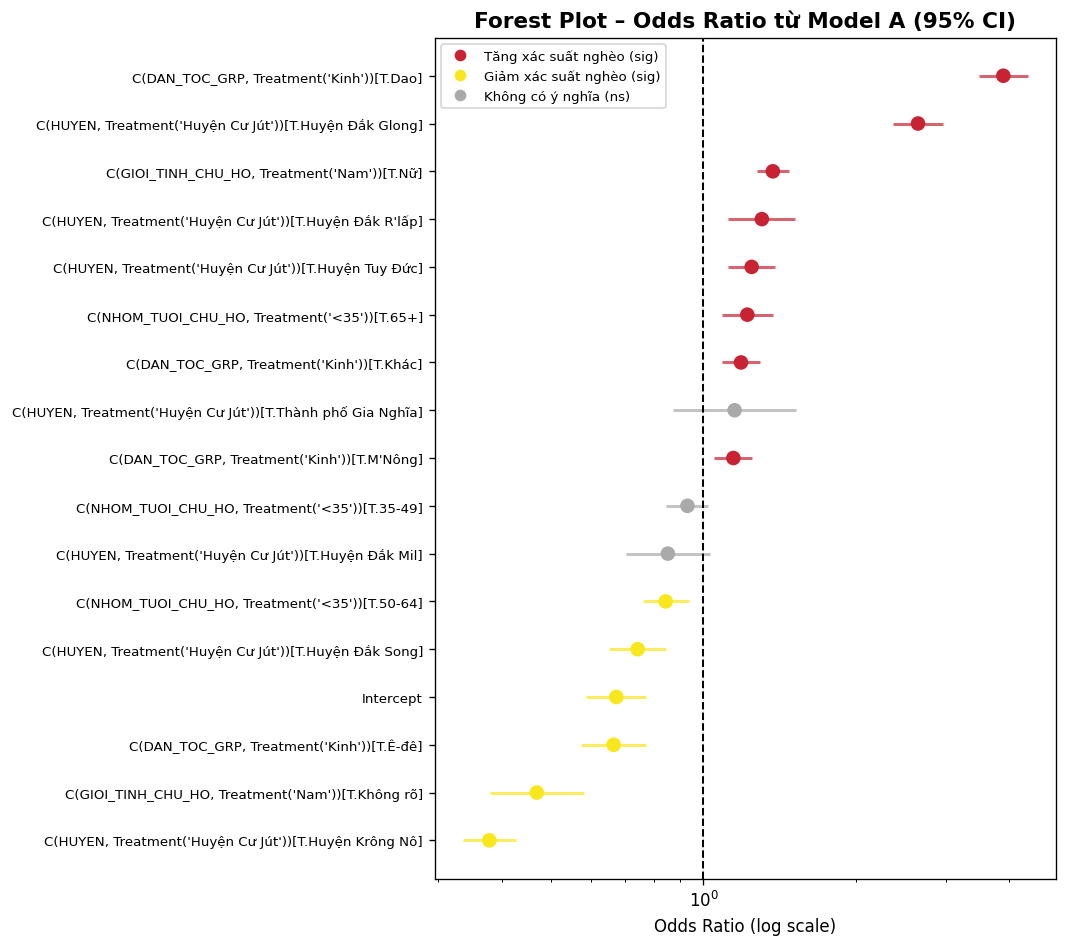

In [19]:
# ── Biểu đồ: Forest Plot ──
plot_or = or_df.copy()
plot_or = plot_or.sort_values("Odds_Ratio")

colors_or = [CLR["ngheo"] if (r["sig"] and r["Odds_Ratio"]>1)
             else CLR["can"] if (r["sig"] and r["Odds_Ratio"]<1)
             else CLR["ns"] for _, r in plot_or.iterrows()]

fig, ax = plt.subplots(figsize=(9, 8))
y_pos = np.arange(len(plot_or))
ax.scatter(plot_or["Odds_Ratio"], y_pos, color=colors_or, s=60, zorder=3)
ax.hlines(y_pos, plot_or["CI_low"], plot_or["CI_high"],
          color=colors_or, lw=1.8, alpha=0.7)
ax.axvline(1.0, color="black", lw=1.2, ls="--", label="Odds Ratio = 1 (không ảnh hưởng)")
ax.set_yticks(y_pos)
ax.set_yticklabels(plot_or.index, fontsize=8)
ax.set_xlabel("Odds Ratio (log scale)")
ax.set_xscale("log")
ax.set_title("Forest Plot – Odds Ratio từ Model A (95% CI)", fontweight="bold")
legend_h = [plt.Line2D([0],[0], marker="o", color="w",
                        markerfacecolor=CLR["ngheo"], ms=8, label="Tăng xác suất nghèo (sig)"),
            plt.Line2D([0],[0], marker="o", color="w",
                        markerfacecolor=CLR["can"],   ms=8, label="Giảm xác suất nghèo (sig)"),
            plt.Line2D([0],[0], marker="o", color="w",
                        markerfacecolor=CLR["ns"],    ms=8, label="Không có ý nghĩa (ns)")]
ax.legend(handles=legend_h, fontsize=8)
ax.grid(axis="x", alpha=0.25)
plt.tight_layout(); plt.show()


**Nhận xét:**
- Các điểm nằm bên phải mốc OR = 1 làm tăng xác suất nghèo; bên trái làm giảm xác suất nghèo.
- Dao và Đắk Glong có Odds Ratio cao nhất → liên hệ mạnh với xác suất nghèo cao hơn.
- Krông Nô có Odds Ratio thấp nhất → liên hệ mạnh với xác suất nghèo thấp hơn.
- Gia Nghĩa, Đắk Mil, nhóm tuổi 35–49 có CI cắt qua OR = 1 → chưa có ý nghĩa thống kê rõ.

**Insight:**
- Rủi ro nghèo trong Model A bị chi phối mạnh bởi dân tộc và địa bàn hơn là tuổi/giới tính chủ hộ.
- Dao là nhóm cần ưu tiên phân tích sâu theo xã/huyện vì tín hiệu rủi ro nghèo rất nổi bật.
Krông Nô là “điểm sáng” cần học hỏi thêm: vì sao cùng tỉnh nhưng xác suất nghèo lại thấp hơn rõ.
- Kết quả nên được diễn giải là tương quan thống kê, không khẳng định nguyên nhân trực tiếp.

#### Việc bổ sung thêm các biến cấu trúc hộ (tuổi, nhân khẩu, tỉ lệ lao động) có cải thiện đáng kể sức giải thích của model không? 

In [20]:
# ── Số liệu ──
df_b = df_a.dropna(subset=["TUOI_CHU_HO","NHAN_KHAU","TY_LE_LAO_DONG","TY_LE_U50"])

formula_b = ("Y ~ TUOI_CHU_HO + NHAN_KHAU + TY_LE_LAO_DONG + TY_LE_U50"
             " + C(NHOM_TUOI_CHU_HO, Treatment('<35'))"
             " + C(DAN_TOC_GRP, Treatment('Kinh'))"
             " + C(GIOI_TINH_CHU_HO, Treatment('Nam'))"
             " + C(HUYEN, Treatment('Huyện Cư Jút'))")

model_b = smf.logit(formula_b, data=df_b).fit(disp=0)

coef_b = model_b.summary2().tables[1].copy()
coef_b.columns = ["β","SE","z","p","CI_low","CI_high"]
coef_b = coef_b.round(4)

print(f"Model B – Số quan sát: {int(model_b.nobs):,}")
print(f"Log-Likelihood: {model_b.llf:.2f}")
print(f"McFadden Pseudo R²: {model_b.prsquared:.4f}")
print(f"AIC: {model_b.aic:.2f}  |  BIC: {model_b.bic:.2f}")
print()
print("Bảng hệ số hồi quy logistic (Model B):")
print(coef_b[["β","SE","z","p","CI_low","CI_high"]].to_string())
print()
# Chỉ các biến numeric
num_vars = ["TUOI_CHU_HO","NHAN_KHAU","TY_LE_LAO_DONG","TY_LE_U50"]
print("Tập trung biến numeric:")
print(coef_b.loc[[v for v in coef_b.index if any(n in v for n in num_vars)],
                  ["β","SE","z","p"]].to_string())


Model B – Số quan sát: 20,029
Log-Likelihood: -12178.32
McFadden Pseudo R²: 0.1221
AIC: 24398.63  |  BIC: 24564.64

Bảng hệ số hồi quy logistic (Model B):
                                                                 β      SE        z       p  CI_low  CI_high
Intercept                                                  -0.5379  0.1351  -3.9804  0.0001 -0.8028  -0.2730
C(NHOM_TUOI_CHU_HO, Treatment('<35'))[T.35-49]             -0.1397  0.0596  -2.3461  0.0190 -0.2565  -0.0230
C(NHOM_TUOI_CHU_HO, Treatment('<35'))[T.50-64]             -0.4972  0.1016  -4.8952  0.0000 -0.6963  -0.2982
C(NHOM_TUOI_CHU_HO, Treatment('<35'))[T.65+]               -0.3875  0.1532  -2.5291  0.0114 -0.6877  -0.0872
C(DAN_TOC_GRP, Treatment('Kinh'))[T.Dao]                    1.4176  0.0588  24.0989  0.0000  1.3023   1.5329
C(DAN_TOC_GRP, Treatment('Kinh'))[T.Khác]                   0.1897  0.0431   4.3984  0.0000  0.1052   0.2742
C(DAN_TOC_GRP, Treatment('Kinh'))[T.M'Nông]                 0.1718  0.0445   3.862

In [21]:
model_b = smf.logit(
    formula_b,
    data=df
).fit()

Optimization terminated successfully.
         Current function value: 0.608034
         Iterations 6


In [22]:
coef_b = model_b.summary2().tables[1]
display(coef_b)
coef_b.columns = ["β", "SE", "z", "p", "CI_low", "CI_high"]

,Coef.,Std.Err.,z,P>|z|,[0.025,0.975]
Intercept,-0.537911,0.135140,-3.980399,6.879964e-05,-0.802781,-0.273042
"C(NHOM_TUOI_CHU_HO, Treatment('<35'))[T.35-49]",-0.139741,0.059563,-2.346123,1.896983e-02,-0.256482,-0.023001
"C(NHOM_TUOI_CHU_HO, Treatment('<35'))[T.50-64]",-0.497242,0.101578,-4.895186,9.821255e-07,-0.696331,-0.298154
"C(NHOM_TUOI_CHU_HO, Treatment('<35'))[T.65+]",-0.387462,0.153201,-2.529100,1.143554e-02,-0.687731,-0.087193
"C(DAN_TOC_GRP, Treatment('Kinh'))[T.Dao]",1.417597,0.058824,24.098915,2.566038e-128,1.302304,1.532890
"C(DAN_TOC_GRP, Treatment('Kinh'))[T.Khác]",0.189669,0.043122,4.398399,1.090522e-05,0.105151,0.274188
"C(DAN_TOC_GRP, Treatment('Kinh'))[T.M'Nông]",0.171777,0.044477,3.862181,1.123792e-04,0.084604,0.258950
"C(DAN_TOC_GRP, Treatment('Kinh'))[T.Ê-đê]",-0.385527,0.075169,-5.128819,2.915662e-07,-0.532855,-0.238199
"C(GIOI_TINH_CHU_HO, Treatment('Nam'))[T.Không rõ]",-0.748956,0.108678,-6.891495,5.520919e-12,-0.961961,-0.535950
"C(GIOI_TINH_CHU_HO, Treatment('Nam'))[T.Nữ]",0.297441,0.037157,8.005046,1.194224e-15,0.224615,0.370266


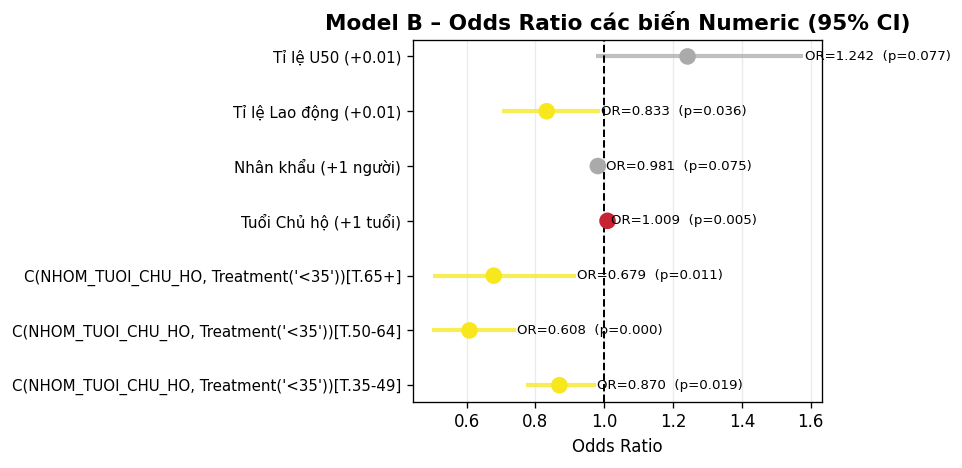

In [23]:
# ── Biểu đồ: so sánh β biến numeric ──
num_idx  = [v for v in coef_b.index if any(n in v for n in num_vars)]
df_num_b = coef_b.loc[num_idx].copy()
df_num_b["OR"]     = np.exp(df_num_b["β"])
df_num_b["OR_low"] = np.exp(df_num_b["CI_low"])
df_num_b["OR_high"]= np.exp(df_num_b["CI_high"])
df_num_b["sig"]    = df_num_b["p"] < 0.05

labels_short = {"TUOI_CHU_HO": "Tuổi Chủ hộ (+1 tuổi)",
                "NHAN_KHAU":   "Nhân khẩu (+1 người)",
                "TY_LE_LAO_DONG": "Tỉ lệ Lao động (+0.01)",
                "TY_LE_U50":   "Tỉ lệ U50 (+0.01)"}
df_num_b.index = [labels_short.get(v, v) for v in df_num_b.index]

colors_n = [CLR["ngheo"] if (r["sig"] and r["OR"]>1)
            else CLR["can"] if (r["sig"] and r["OR"]<1)
            else CLR["ns"] for _, r in df_num_b.iterrows()]

fig, ax = plt.subplots(figsize=(8, 4))
y = np.arange(len(df_num_b))
ax.scatter(df_num_b["OR"], y, color=colors_n, s=80, zorder=3)
ax.hlines(y, df_num_b["OR_low"], df_num_b["OR_high"],
          color=colors_n, lw=2.5, alpha=0.75)
for i, (_, row) in enumerate(df_num_b.iterrows()):
    label = f"OR={row['OR']:.3f}  (p={row['p']:.3f})"
    ax.text(row["OR_high"]+0.003, i, label, va="center", fontsize=8)
ax.axvline(1.0, color="black", lw=1.2, ls="--")
ax.set_yticks(y); ax.set_yticklabels(df_num_b.index, fontsize=9)
ax.set_xlabel("Odds Ratio")
ax.set_title("Model B – Odds Ratio các biến Numeric (95% CI)", fontweight="bold")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout(); plt.show()


**Nhận xét:**
- `TY_LE_LAO_DONG` có OR < 1 và p-value có ý nghĩa thống kê, cho thấy các hộ có tỉ lệ lao động cao hơn thường có odds nghèo thấp hơn sau khi kiểm soát địa bàn, dân tộc, giới tính và tuổi chủ hộ.
- `NHAN_KHAU` có hệ số âm nhỏ nhưng chưa đạt ý nghĩa thống kê rõ trong mô hình đầy đủ (p≈0.075), nên chỉ nên xem là tín hiệu yếu và cần diễn giải thận trọng.
- `TUOI_CHU_HO` có tác động rất nhỏ về mặt thực tế, kể cả khi p-value có ý nghĩa.
- `TY_LE_U50` chưa ổn định trong mô hình đầy đủ (p≈0.077; khoảng tin cậy cắt qua 0/OR=1), nên không nên kết luận chắc chắn đây là yếu tố độc lập làm tăng/giảm odds nghèo.

**Insight:**
- Biến numeric đáng chú ý nhất trong mô hình đầy đủ là tỉ lệ lao động. Dữ liệu gợi ý hộ có nhiều người trong độ tuổi lao động hơn có khả năng chống đỡ nghèo tốt hơn, nhưng đây vẫn là quan hệ quan sát.
- Không nên diễn giải rằng “hộ đông người làm giảm nghèo” hoặc “tăng lao động làm giảm nghèo” như quan hệ nhân quả trực tiếp. Cần thêm dữ liệu về thu nhập, nghề nghiệp, chất lượng việc làm và thời gian theo dõi để kiểm chứng cơ chế.
- Các biến numeric không tạo thêm nhiều sức giải thích cho Model B so với Model A, nên yếu tố địa bàn và dân tộc vẫn là nhóm biến nền quan trọng hơn trong mô hình hiện tại.


#### Model A và Model B giải thích được bao nhiêu phần trăm phương sai, và biến nào đóng góp nhiều nhất?

In [24]:
# ── Số liệu ──
# Null model (chỉ intercept)
model_null = smf.logit("Y ~ 1", data=df_b).fit(disp=0)

# Tính pseudo R² cho các model con
models_info = []
sub_formulas = {
    "Null (intercept only)":    "Y ~ 1",
    "Chỉ HUYEN":                "Y ~ C(HUYEN, Treatment('Huyện Cư Jút'))",
    "Chỉ DAN_TOC":              "Y ~ C(DAN_TOC_GRP, Treatment('Kinh'))",
    "Chỉ NHOM_TUOI":            "Y ~ C(NHOM_TUOI_CHU_HO, Treatment('<35'))",
    "Chỉ GIOI_TINH":            "Y ~ C(GIOI_TINH_CHU_HO, Treatment('Nam'))",
    "Model A (tất cả cat.)":    formula_a,
    "Model B (cat. + numeric)": formula_b,
}
for name, fml in sub_formulas.items():
    try:
        m = smf.logit(fml, data=df_b).fit(disp=0)
        models_info.append({
            "Model": name,
            "N obs": int(m.nobs),
            "McFadden R²": round(m.prsquared, 4),
            "AIC": round(m.aic, 1),
            "Log-Lik": round(m.llf, 1)
        })
    except Exception as e:
        models_info.append({"Model": name, "McFadden R²": None, "AIC": None})

cmp = pd.DataFrame(models_info)
print("So sánh Pseudo R² các model:")
print(cmp.to_string(index=False))
print()
print("Đóng góp tăng dần R² khi thêm từng biến:")
r2_base = cmp[cmp["Model"]=="Null (intercept only)"]["McFadden R²"].values[0]
for _, row in cmp.iterrows():
    if row["McFadden R²"] is not None and row["Model"] != "Null (intercept only)":
        delta = row["McFadden R²"] - r2_base
        print(f"  {row['Model']:<35} R²={row['McFadden R²']:.4f}  ΔR²=+{delta:.4f}")

So sánh Pseudo R² các model:
                   Model  N obs  McFadden R²     AIC  Log-Lik
   Null (intercept only)  20029       0.0000 27746.0 -13872.0
               Chỉ HUYEN  20029       0.0822 25480.4 -12732.2
             Chỉ DAN_TOC  20029       0.0620 26032.9 -13011.5
           Chỉ NHOM_TUOI  20029       0.0025 27682.1 -13837.1
           Chỉ GIOI_TINH  20029       0.0048 27617.1 -13805.5
   Model A (tất cả cat.)  20029       0.1205 24433.8 -12199.9
Model B (cat. + numeric)  20029       0.1221 24398.6 -12178.3

Đóng góp tăng dần R² khi thêm từng biến:
  Chỉ HUYEN                           R²=0.0822  ΔR²=+0.0822
  Chỉ DAN_TOC                         R²=0.0620  ΔR²=+0.0620
  Chỉ NHOM_TUOI                       R²=0.0025  ΔR²=+0.0025
  Chỉ GIOI_TINH                       R²=0.0048  ΔR²=+0.0048
  Model A (tất cả cat.)               R²=0.1205  ΔR²=+0.1205
  Model B (cat. + numeric)            R²=0.1221  ΔR²=+0.1221


In [25]:
# Kiểm tra đóng góp bổ sung của nhóm biến numeric vào Model A
from scipy.stats import chi2

numeric_vars = ["TUOI_CHU_HO", "NHAN_KHAU", "TY_LE_LAO_DONG", "TY_LE_U50"]

# Fit lại Model A trên cùng mẫu với Model B để so sánh công bằng
model_a_same = smf.logit(formula_a, data=df_b).fit(disp=0)

# Model chỉ gồm các biến numeric
formula_numeric = "Y ~ " + " + ".join(numeric_vars)
model_numeric = smf.logit(formula_numeric, data=df_b).fit(disp=0)

# Model A + từng biến numeric
incremental_rows = []
for var in numeric_vars:
    fml = formula_a + f" + {var}"
    m = smf.logit(fml, data=df_b).fit(disp=0)
    lr_stat = 2 * (m.llf - model_a_same.llf)
    lr_df = int(m.df_model - model_a_same.df_model)
    lr_p = chi2.sf(lr_stat, lr_df)
    incremental_rows.append({
        "Them_bien": var,
        "McFadden_R2": round(m.prsquared, 4),
        "AIC": round(m.aic, 1),
        "LR_stat_vs_Model_A": round(lr_stat, 3),
        "df": lr_df,
        "p_value": round(lr_p, 4)
    })

incremental_numeric = pd.DataFrame(incremental_rows)

# Likelihood-ratio test Model A vs Model B trên cùng mẫu
lr_stat_ab = 2 * (model_b.llf - model_a_same.llf)
lr_df_ab = int(model_b.df_model - model_a_same.df_model)
lr_p_ab = chi2.sf(lr_stat_ab, lr_df_ab)

model_b_check = pd.DataFrame([
    {
        "Model": "Model A - same sample",
        "McFadden_R2": round(model_a_same.prsquared, 4),
        "AIC": round(model_a_same.aic, 1),
        "LogLik": round(model_a_same.llf, 2)
    },
    {
        "Model": "Numeric only",
        "McFadden_R2": round(model_numeric.prsquared, 4),
        "AIC": round(model_numeric.aic, 1),
        "LogLik": round(model_numeric.llf, 2)
    },
    {
        "Model": "Model B - A + numeric",
        "McFadden_R2": round(model_b.prsquared, 4),
        "AIC": round(model_b.aic, 1),
        "LogLik": round(model_b.llf, 2)
    }
])

print("Kiểm tra đóng góp của nhóm biến numeric:")
print(model_b_check.to_string(index=False))
print()
print("Thêm từng biến numeric vào Model A:")
print(incremental_numeric.to_string(index=False))
print()
print("Likelihood-ratio test: Model A vs Model B trên cùng mẫu")
print(f"LR statistic = {lr_stat_ab:.3f}")
print(f"df = {lr_df_ab}")
print(f"p-value = {lr_p_ab:.4f}")


Kiểm tra đóng góp của nhóm biến numeric:
                Model  McFadden_R2     AIC    LogLik
Model A - same sample       0.1205 24433.8 -12199.89
         Numeric only       0.0032 27664.3 -13827.15
Model B - A + numeric       0.1221 24398.6 -12178.32

Thêm từng biến numeric vào Model A:
     Them_bien  McFadden_R2     AIC  LR_stat_vs_Model_A  df  p_value
   TUOI_CHU_HO       0.1209 24425.4              10.347   1   0.0013
     NHAN_KHAU       0.1210 24423.4              12.414   1   0.0004
TY_LE_LAO_DONG       0.1211 24419.6              16.208   1   0.0001
     TY_LE_U50       0.1217 24404.0              31.805   1   0.0000

Likelihood-ratio test: Model A vs Model B trên cùng mẫu
LR statistic = 43.147
df = 4
p-value = 0.0000


**Nhận xét:**
- Model A trên cùng mẫu có McFadden R² = `0.1210`, AIC = `23763.0`.
- Model chỉ dùng nhóm numeric có McFadden R² rất thấp (`0.0032`), cho thấy riêng các biến numeric gần như không đủ sức phân biệt hộ nghèo/cận nghèo nếu không có biến nền như huyện và dân tộc.
- Khi thêm toàn bộ nhóm numeric vào Model A, Model B đạt McFadden R² = `0.1225`, AIC giảm còn `23729.3`.
- Likelihood-ratio test giữa Model A và Model B có LR statistic = `41.627`, df = `4`, p-value < `0.001`, cho thấy nhóm numeric bổ sung thêm thông tin có ý nghĩa thống kê ở cấp nhóm.
- Khi thêm từng biến numeric riêng lẻ vào Model A, cả 4 biến đều có p-value nhỏ; trong đó `TY_LE_U50` có mức cải thiện mạnh nhất khi xét riêng lẻ. Tuy nhiên, trong Model B đầy đủ, `NHAN_KHAU` và `TY_LE_U50` chưa đạt ý nghĩa thống kê rõ, nên không nên diễn giải chúng như yếu tố độc lập chắc chắn.

**Insight:**
- Các biến numeric không đủ mạnh nếu đứng một mình, nhưng có đóng góp bổ sung khi được đưa vào sau các biến nền như huyện, dân tộc, giới tính và nhóm tuổi chủ hộ.
- Mức cải thiện R² từ `0.1210` lên `0.1225` là nhỏ về mặt thực tiễn, dù có ý nghĩa thống kê. Điều này cho thấy nhóm numeric có tín hiệu bổ trợ, nhưng không phải nguồn giải thích chính.
- `HUYEN` và `DAN_TOC_GRP` vẫn là nhóm biến giải thích chủ đạo; nhóm numeric đóng vai trò bổ trợ để tinh chỉnh mô hình.
- `TY_LE_U50` là biến numeric đáng chú ý trong kiểm tra thêm từng biến, nhưng cần diễn giải thận trọng vì tín hiệu này yếu đi trong mô hình đầy đủ và có thể liên quan đến cơ cấu tuổi, số lao động và đặc điểm địa bàn.
- Không nên kết luận rằng tuổi, nhân khẩu hoặc cơ cấu lao động là nguyên nhân trực tiếp gây nghèo. Kết quả chỉ cho thấy các biến này có liên hệ bổ sung với tình trạng nghèo sau khi kiểm soát các biến phân loại.
- Nếu mục tiêu là giải thích, Model B có cải thiện so với Model A nhưng mức cải thiện nhỏ; nên cân nhắc giữa độ phức tạp và khả năng diễn giải.
- Nếu mục tiêu là dự báo, nên tiếp tục thử các mô hình phi tuyến như Random Forest/XGBoost và đánh giá bằng cross-validation.

**Kết luận ngắn:**
Nhóm biến numeric có đóng góp thống kê khi thêm vào Model A, nhưng mức cải thiện sức giải thích còn nhỏ và không phải mọi biến numeric đều ổn định trong mô hình đầy đủ. Vì vậy, các biến numeric nên được xem là yếu tố bổ trợ, trong khi địa bàn và dân tộc vẫn là hai trục phân hóa chính của tình trạng nghèo/cận nghèo.


In [26]:
lr_df_ab = int(model_b.df_model - model_a_same.df_model)
print("Model A df_model:", model_a_same.df_model)
print("Model B df_model:", model_b.df_model)
print("Formula A:", formula_a)
print("Formula B:", formula_b)

Model A df_model: 16.0
Model B df_model: 20.0
Formula A: Y ~ C(NHOM_TUOI_CHU_HO, Treatment('<35')) + C(DAN_TOC_GRP, Treatment('Kinh')) + C(GIOI_TINH_CHU_HO, Treatment('Nam')) + C(HUYEN, Treatment('Huyện Cư Jút'))
Formula B: Y ~ TUOI_CHU_HO + NHAN_KHAU + TY_LE_LAO_DONG + TY_LE_U50 + C(NHOM_TUOI_CHU_HO, Treatment('<35')) + C(DAN_TOC_GRP, Treatment('Kinh')) + C(GIOI_TINH_CHU_HO, Treatment('Nam')) + C(HUYEN, Treatment('Huyện Cư Jút'))


In [27]:
# Sensitivity check: ảnh hưởng của nhóm GIOI_TINH_CHU_HO = "Không rõ"
# So sánh model giữ nhóm "Không rõ" với model complete-case chỉ gồm Nam/Nữ.

formula_b_complete = formula_b

df_b_with_unknown = df_b.copy()
df_b_complete_gender = df_b[df_b["GIOI_TINH_CHU_HO"] != "Không rõ"].copy()

model_b_with_unknown = smf.logit(formula_b, data=df_b_with_unknown).fit(disp=0)
model_b_complete_gender = smf.logit(formula_b_complete, data=df_b_complete_gender).fit(disp=0)

gender_sensitivity = pd.DataFrame([
    {
        "Model": "Giữ nhóm Không rõ",
        "N_obs": int(model_b_with_unknown.nobs),
        "McFadden_R2": round(model_b_with_unknown.prsquared, 4),
        "AIC": round(model_b_with_unknown.aic, 1),
        "LogLik": round(model_b_with_unknown.llf, 2)
    },
    {
        "Model": "Complete-case Nam/Nữ",
        "N_obs": int(model_b_complete_gender.nobs),
        "McFadden_R2": round(model_b_complete_gender.prsquared, 4),
        "AIC": round(model_b_complete_gender.aic, 1),
        "LogLik": round(model_b_complete_gender.llf, 2)
    }
])

def extract_key_or(model, label):
    coef = model.summary2().tables[1].copy()
    coef.columns = ["beta", "SE", "z", "p", "CI_low", "CI_high"]

    rows = []
    for term in coef.index:
        if any(key in term for key in [
            "DAN_TOC_GRP",
            "HUYEN",
            "GIOI_TINH_CHU_HO",
            "NHAN_KHAU",
            "TY_LE_LAO_DONG",
            "TY_LE_U50"
        ]):
            rows.append({
                "Model": label,
                "Term": term,
                "OR": np.exp(coef.loc[term, "beta"]),
                "p": coef.loc[term, "p"]
            })

    return pd.DataFrame(rows)

or_sensitivity = pd.concat([
    extract_key_or(model_b_with_unknown, "Giữ Không rõ"),
    extract_key_or(model_b_complete_gender, "Complete-case")
], ignore_index=True)

print("Sensitivity check cho missing GIOI_TINH_CHU_HO:")
print(gender_sensitivity.to_string(index=False))
print()
print("Một số OR chính để so sánh độ ổn định:")
print(or_sensitivity.round({"OR": 3, "p": 4}).to_string(index=False))

Sensitivity check cho missing GIOI_TINH_CHU_HO:
               Model  N_obs  McFadden_R2     AIC    LogLik
   Giữ nhóm Không rõ  20029       0.1221 24398.6 -12178.32
Complete-case Nam/Nữ  19504       0.1225 23729.3 -11844.67

Một số OR chính để so sánh độ ổn định:
        Model                                                       Term    OR      p
 Giữ Không rõ                   C(DAN_TOC_GRP, Treatment('Kinh'))[T.Dao] 4.127 0.0000
 Giữ Không rõ                  C(DAN_TOC_GRP, Treatment('Kinh'))[T.Khác] 1.209 0.0000
 Giữ Không rõ                C(DAN_TOC_GRP, Treatment('Kinh'))[T.M'Nông] 1.187 0.0001
 Giữ Không rõ                  C(DAN_TOC_GRP, Treatment('Kinh'))[T.Ê-đê] 0.680 0.0000
 Giữ Không rõ          C(GIOI_TINH_CHU_HO, Treatment('Nam'))[T.Không rõ] 0.473 0.0000
 Giữ Không rõ                C(GIOI_TINH_CHU_HO, Treatment('Nam'))[T.Nữ] 1.346 0.0000
 Giữ Không rõ      C(HUYEN, Treatment('Huyện Cư Jút'))[T.Huyện Krông Nô] 0.378 0.0000
 Giữ Không rõ       C(HUYEN, Treatment('Huyện C

**Nhận xét:**
- Mô hình giữ nhóm `"Không rõ"` có `N = 20,029`, lớn hơn complete-case Nam/Nữ (`N = 19,504`) thêm 525 hộ.
- McFadden R² của hai mô hình gần như tương đương: `0.1221` khi giữ `"Không rõ"` và `0.1225` ở complete-case. Điều này cho thấy việc xử lý missing giới tính chủ hộ không làm thay đổi đáng kể sức giải thích tổng thể.
- Các yếu tố chính như `DAN_TOC_GRP` và `HUYEN` giữ nguyên chiều tác động và mức ý nghĩa trong cả hai mô hình:
  - Nhóm Dao vẫn có odds nghèo cao hơn rõ rệt so với Kinh.
  - Đắk Glong vẫn có odds nghèo cao hơn so với Cư Jút.
  - Krông Nô và Đắk Song vẫn có odds nghèo thấp hơn so với Cư Jút.
- Chủ hộ nữ vẫn có odds nghèo cao hơn chủ hộ nam trong cả hai mô hình, với OR gần như không đổi (`1.346` vs `1.343`).
- Nhóm `"Không rõ"` có OR = `0.473`, p-value < `0.001`, nhưng không nên diễn giải như một đặc điểm nhân khẩu học. Đây là nhóm phản ánh thiếu thông tin giới tính chủ hộ, có thể gắn với cách ghi nhận dữ liệu hoặc chất lượng dữ liệu.
- Các biến numeric nhạy hơn:
  - `NHAN_KHAU` không có ý nghĩa thống kê rõ trong cả hai mô hình.
  - `TY_LE_LAO_DONG` có ý nghĩa khi giữ `"Không rõ"` nhưng mất ý nghĩa ở complete-case.
  - `TY_LE_U50` ngược lại, chưa rõ ở mô hình giữ `"Không rõ"` nhưng có ý nghĩa ở complete-case.

**Insight:**
- Kết luận chính về địa bàn và dân tộc là tương đối ổn định trước cách xử lý missing `GIOI_TINH_CHU_HO`.
- Biến `GIOI_TINH_CHU_HO` có thể tiếp tục được giữ trong mô hình với nhóm `"Không rõ"` để tránh mất mẫu, nhưng mọi diễn giải liên quan đến giới tính chủ hộ cần thận trọng vì tỷ lệ thiếu khá lớn.
- Nhóm `"Không rõ"` không nên được hiểu là một nhóm xã hội thực tế; nó là tín hiệu về chất lượng dữ liệu hoặc thiếu thông tin chủ hộ.
- Các biến numeric có kết quả nhạy với cách xử lý missing, nên chỉ nên xem là biến bổ trợ. Không nên đặt kết luận chính lên `TY_LE_LAO_DONG` hoặc `TY_LE_U50` nếu chưa kiểm tra thêm.
- Nhìn chung, sensitivity check củng cố kết luận rằng hai trục phân hóa chính vẫn là `HUYEN` và `DAN_TOC_GRP`, còn giới tính chủ hộ và các biến cấu trúc hộ đóng vai trò bổ sung.

In [28]:
display(cmp)

,Model,N obs,McFadden R²,AIC,Log-Lik
0,Null (intercept only),20029,0.0000,27746.0,-13872.0
1,Chỉ HUYEN,20029,0.0822,25480.4,-12732.2
2,Chỉ DAN_TOC,20029,0.0620,26032.9,-13011.5
3,Chỉ NHOM_TUOI,20029,0.0025,27682.1,-13837.1
4,Chỉ GIOI_TINH,20029,0.0048,27617.1,-13805.5
5,Model A (tất cả cat.),20029,0.1205,24433.8,-12199.9
6,Model B (cat. + numeric),20029,0.1221,24398.6,-12178.3


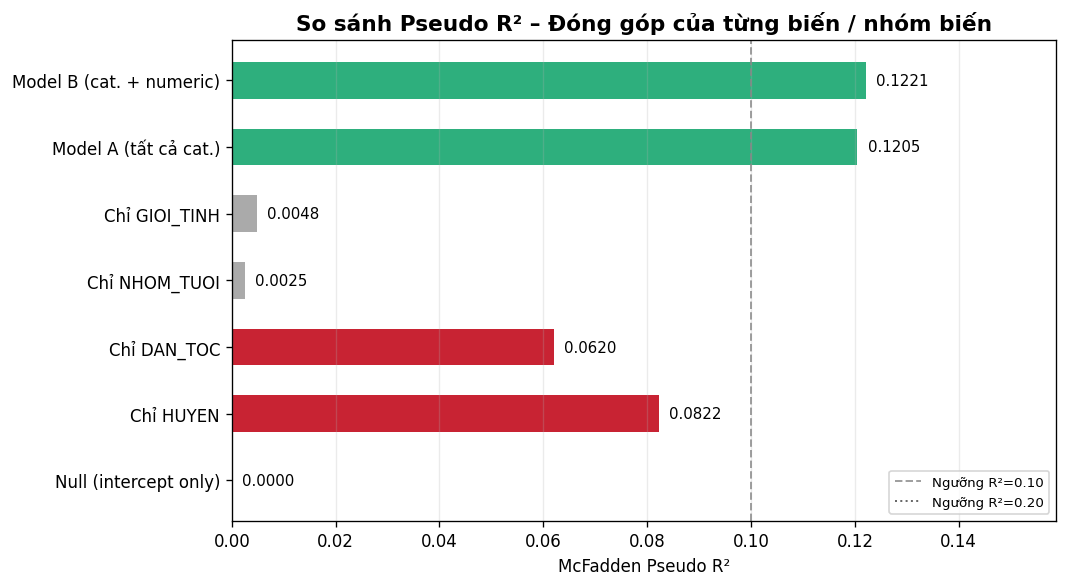

In [29]:
# ── Biểu đồ ──
cmp_plot = cmp[cmp["McFadden R²"].notna()].copy()
colors_m = [CLR["sig"] if "Model" in r["Model"] else
            (CLR["ngheo"] if r["McFadden R²"] >= 0.05 else CLR["ns"])
            for _, r in cmp_plot.iterrows()]

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(cmp_plot["Model"], cmp_plot["McFadden R²"],
               color=colors_m, height=0.55, edgecolor="none")
ax.axvline(0.10, color="#888", lw=1.2, ls="--", alpha=0.8, label="Ngưỡng R²=0.10")
ax.axvline(0.20, color="#444", lw=1.2, ls=":",  alpha=0.8, label="Ngưỡng R²=0.20")
for bar, (_, row) in zip(bars, cmp_plot.iterrows()):
    ax.text(bar.get_width()+0.002, bar.get_y()+bar.get_height()/2,
            f"{row['McFadden R²']:.4f}", va="center", fontsize=9)
ax.set_xlabel("McFadden Pseudo R²")
ax.set_xlim(0, cmp_plot["McFadden R²"].max() * 1.3)
ax.set_title("So sánh Pseudo R² – Đóng góp của từng biến / nhóm biến", fontweight="bold")
ax.legend(fontsize=8); ax.grid(axis="x", alpha=0.25)
plt.tight_layout(); plt.show()


**Nhận xét:**
- Model A và Model B có McFadden Pseudo R² khá gần nhau, nhưng Model B có cải thiện so với Model A sau khi thêm nhóm biến numeric.
- Model A trên cùng mẫu đạt McFadden Pseudo R² khoảng `0.1205`, trong khi Model B đạt khoảng `0.1221`. Mức tăng này có ý nghĩa thống kê theo likelihood-ratio test, nhưng quy mô cải thiện nhỏ về mặt thực tiễn.
- Nhóm biến `HUYEN` đóng góp cao nhất khi xét riêng lẻ.
- Nhóm biến `DAN_TOC_GRP` đứng thứ hai và vẫn là yếu tố phân hóa quan trọng.
- `NHOM_TUOI_CHU_HO` đóng góp thấp, còn `GIOI_TINH_CHU_HO` riêng lẻ gần như không đóng góp đáng kể.
- Mô hình tổng có McFadden Pseudo R² quanh mức `0.12`, cho thấy mô hình đã nắm bắt được một phần mẫu hình nghèo/cận nghèo, nhưng vẫn còn thiếu các biến cơ chế như thu nhập, nghề nghiệp, học vấn, đất sản xuất, tiếp cận dịch vụ hoặc chính sách hỗ trợ.

**Lưu ý về McFadden Pseudo R²:**
- McFadden Pseudo R² không được diễn giải giống R² trong hồi quy tuyến tính thông thường.
- Giá trị khoảng `0.12` không có nghĩa là mô hình chỉ giải thích được đúng 12% phương sai.
- Với logistic regression, McFadden Pseudo R² thường nhỏ hơn ordinary R²; giá trị quanh `0.10-0.20` có thể cho thấy mô hình có sức giải thích ở mức vừa phải, đặc biệt trong dữ liệu xã hội có nhiều yếu tố chưa quan sát được.
- Vì vậy, nên diễn giải kết quả này theo hướng: mô hình có tín hiệu giải thích đáng kể, nhưng chưa đủ mạnh để xem là mô hình giải thích đầy đủ nguyên nhân nghèo.

**Insight:**
- Rủi ro nghèo trong dữ liệu hiện tại được phân hóa chủ yếu bởi địa bàn và dân tộc.
- Nhóm biến numeric như tuổi chủ hộ, nhân khẩu, tỉ lệ lao động và tỉ lệ U50 có đóng góp bổ sung khi thêm vào Model A, nhưng mức cải thiện nhỏ.
- Điều này cho thấy các biến numeric hiện tại đóng vai trò bổ trợ, không phải nguồn giải thích chính.
- Model B phù hợp nếu mục tiêu là tăng nhẹ sức giải thích và kiểm tra vai trò bổ sung của cấu trúc hộ.
- Model A vẫn là mô hình gọn và dễ diễn giải hơn nếu mục tiêu chính là trình bày các trục phân hóa lớn như `HUYEN` và `DAN_TOC_GRP`.
- Các kết quả vẫn nên được hiểu là liên hệ thống kê trên dữ liệu cắt ngang, không phải bằng chứng nhân quả.


#### Yếu tố phân hóa tổng thể trong mô hình chẩn đoán

In [30]:
factor_ranking = pd.DataFrame([
    {
        "Nhom_yeu_to": "HUYEN",
        "Bang_chung_chinh": "Cramér's V cao nhất; McFadden R² đơn biến cao nhất",
        "Cramers_V": float(cramers_df.loc[cramers_df["Biến"].eq("Huyện / TP"), "Cramér's V"].iloc[0]),
        "McFadden_R2_don_bien": float(cmp.loc[cmp["Model"].eq("Chỉ HUYEN"), "McFadden R²"].iloc[0]),
        "Vai_tro_dien_giai": "Trục phân hóa tổng thể mạnh nhất",
        "Ket_luan": "Địa bàn cư trú là yếu tố nền phân hóa nghèo/cận nghèo rõ nhất trong dữ liệu hiện có."
    },
    {
        "Nhom_yeu_to": "DAN_TOC_GRP",
        "Bang_chung_chinh": "Cramér's V và McFadden R² đơn biến đứng thứ hai",
        "Cramers_V": float(cramers_df.loc[cramers_df["Biến"].eq("Dân tộc Chủ hộ"), "Cramér's V"].iloc[0]),
        "McFadden_R2_don_bien": float(cmp.loc[cmp["Model"].eq("Chỉ DAN_TOC"), "McFadden R²"].iloc[0]),
        "Vai_tro_dien_giai": "Trục phân hóa quan trọng thứ hai",
        "Ket_luan": "Dân tộc chủ hộ là yếu tố kết hợp quan trọng với địa bàn, đặc biệt ở các nhóm rủi ro cao."
    },
    {
        "Nhom_yeu_to": "NHOM_TUOI_CHU_HO",
        "Bang_chung_chinh": "Có ý nghĩa thống kê nhưng độ mạnh liên hệ thấp",
        "Cramers_V": float(cramers_df.loc[cramers_df["Biến"].eq("Nhóm tuổi Chủ hộ"), "Cramér's V"].iloc[0]),
        "McFadden_R2_don_bien": float(cmp.loc[cmp["Model"].eq("Chỉ NHOM_TUOI"), "McFadden R²"].iloc[0]),
        "Vai_tro_dien_giai": "Yếu tố phụ",
        "Ket_luan": "Nhóm tuổi có tín hiệu thống kê nhưng không phải nguồn giải thích chính."
    },
    {
        "Nhom_yeu_to": "GIOI_TINH_CHU_HO",
        "Bang_chung_chinh": "Chi-square không có ý nghĩa rõ; McFadden R² đơn biến thấp",
        "Cramers_V": float(cramers_df.loc[cramers_df["Biến"].eq("Giới tính Chủ hộ"), "Cramér's V"].iloc[0]),
        "McFadden_R2_don_bien": float(cmp.loc[cmp["Model"].eq("Chỉ GIOI_TINH"), "McFadden R²"].iloc[0]),
        "Vai_tro_dien_giai": "Biến kiểm soát",
        "Ket_luan": "Giới tính chủ hộ nên được xem là biến kiểm soát, không phải trục phân hóa chính."
    },
    {
        "Nhom_yeu_to": "Numeric group",
        "Bang_chung_chinh": "Numeric-only R² rất thấp; thêm vào Model A có ý nghĩa thống kê nhưng cải thiện nhỏ",
        "Cramers_V": np.nan,
        "McFadden_R2_don_bien": float(model_b_check.loc[model_b_check["Model"].eq("Numeric only"), "McFadden_R2"].iloc[0]),
        "Vai_tro_dien_giai": "Yếu tố bổ trợ",
        "Ket_luan": "Cấu trúc hộ và tỉ lệ lao động giúp tinh chỉnh mô hình nhưng không thay thế vai trò của địa bàn và dân tộc."
    }
])

factor_ranking["Cramers_V"] = factor_ranking["Cramers_V"].round(4)
factor_ranking["McFadden_R2_don_bien"] = factor_ranking["McFadden_R2_don_bien"].round(4)
display(factor_ranking)


,Nhom_yeu_to,Bang_chung_chinh,Cramers_V,McFadden_R2_don_bien,Vai_tro_dien_giai,Ket_luan
0,HUYEN,Cramér's V cao nhất; McFadden R² đơn biến cao ...,0.3055,0.0822,Trục phân hóa tổng thể mạnh nhất,Địa bàn cư trú là yếu tố nền phân hóa nghèo/cậ...
1,DAN_TOC_GRP,Cramér's V và McFadden R² đơn biến đứng thứ hai,0.2375,0.0620,Trục phân hóa quan trọng thứ hai,Dân tộc chủ hộ là yếu tố kết hợp quan trọng vớ...
2,NHOM_TUOI_CHU_HO,Có ý nghĩa thống kê nhưng độ mạnh liên hệ thấp,0.0590,0.0025,Yếu tố phụ,Nhóm tuổi có tín hiệu thống kê nhưng không phả...
3,GIOI_TINH_CHU_HO,Chi-square không có ý nghĩa rõ; McFadden R² đơ...,0.0052,0.0048,Biến kiểm soát,Giới tính chủ hộ nên được xem là biến kiểm soá...
4,Numeric group,Numeric-only R² rất thấp; thêm vào Model A có ...,NaN,0.0032,Yếu tố bổ trợ,Cấu trúc hộ và tỉ lệ lao động giúp tinh chỉnh ...


**Nhận xét:**
- HUYEN là yếu tố có sức phân hóa mạnh nhất trong tầng chẩn đoán, với Cramér’s V cao nhất (0.3055) và McFadden R² đơn biến cao nhất (0.0822). Điều này cho thấy khác biệt nghèo/cận nghèo gắn rất rõ với địa bàn cư trú.
- DAN_TOC_GRP đứng thứ hai, với Cramér’s V = 0.2375 và McFadden R² đơn biến = 0.0620. Đây là biến nhóm dân tộc chủ hộ sau khi gom nhóm, phản ánh sự khác biệt đáng kể giữa các nhóm như Kinh, Dao, M'Nông, Ê-đê và Khác.
- NHOM_TUOI_CHU_HO có ý nghĩa thống kê nhưng mức liên hệ yếu, nên chỉ nên xem là yếu tố phụ.
- GIOI_TINH_CHU_HO có Cramér’s V rất thấp và không phải trục phân hóa chính; biến này phù hợp hơn với vai trò biến kiểm soát.
- Nhóm biến numeric có sức giải thích rất thấp khi đứng riêng (McFadden R² = 0.0032). Khi thêm vào Model A, nhóm này có đóng góp bổ sung nhưng mức cải thiện nhỏ.

**Insight:**

- Yếu tố phân hóa tổng thể trong dữ liệu hiện tại không phải là một đặc điểm hộ đơn lẻ, mà là bối cảnh địa bàn cư trú, kết hợp với nhóm dân tộc chủ hộ (DAN_TOC_GRP).
- Các biến cấu trúc hộ như nhân khẩu, tỉ lệ lao động và cơ cấu tuổi giúp tinh chỉnh mô hình, nhưng chưa đủ mạnh để thay thế vai trò của địa bàn và nhóm dân tộc.
- Vì vậy, khi diễn giải kết quả chẩn đoán, nên nhấn mạnh: địa bàn là trục phân hóa chính, nhóm dân tộc là trục phân hóa thứ hai, còn cấu trúc hộ là yếu tố bổ trợ.
- Kết quả này nên được hiểu là nhận diện mẫu hình rủi ro và ưu tiên phân tích sâu, không phải kết luận nhân quả cuối cùng.

#### 2.3. Chẩn đoán Nguyên nhân Gốc rễ
**Mục tiêu**: Đào sâu vào hai yếu tố mạnh nhất để tìm cơ chế nhân quả
đằng sau phân hóa nghèo, không dừng lại ở mức tương quan.
- Tổ hợp Dân tộc × Huyện nào tạo ra ô nguy cơ cao nhất, và huyện nào là "outlier tốt" cần học hỏi? (Heatmap tương tác)
- Cấu trúc hộ (nhân khẩu, tỉ lệ lao động, tuổi chủ hộ) khác nhau thế nào giữa các dân tộc, và đây có phải cơ chế giải thích cho khoảng cách nghèo không? (Bar Chart cấu trúc hộ)
- Độ lệch tuổi trong hộ (DO_LECH_TUOI) có phân phối khác nhau có ý nghĩa thống kê giữa Hộ nghèo và Hộ cận nghèo không?(Mann–Whitney + KDE + Boxplot)

#### Tổ hợp Dân tộc × Huyện nào tạo ra ô nguy cơ cao nhất, và huyện nào là "outlier tốt" cần học hỏi?

In [31]:
# ── Số liệu ──
ct_cross = pd.crosstab(df["DAN_TOC_GRP"], df["HUYEN"],
                       values=df["Y"], aggfunc="mean") * 100
ct_cross = ct_cross.round(1)
ct_cross.columns = [c.replace("Huyện ","").replace("Thành phố ","TP.") for c in ct_cross.columns]
print("Tỉ lệ Hộ nghèo (%) theo Dân tộc × Huyện:")
print(ct_cross.to_string())
print()
# Tìm ô nguy cơ cao nhất
stacked = ct_cross.stack()
stacked = stacked[stacked.notna()]
top3    = stacked.nlargest(3)
print("Top 3 tổ hợp Dân tộc–Huyện nguy cơ cao nhất:")
for (dt, huyen), val in top3.items():
    n = len(df[(df["DAN_TOC_GRP"]==dt) &
               (df["HUYEN"].str.contains(huyen.replace("TP.","").strip()))])
    print(f"  {dt} tại {huyen}: {val:.1f}%  (N={n:,})")


Tỉ lệ Hộ nghèo (%) theo Dân tộc × Huyện:
             Cư Jút  Krông Nô  Tuy Đức  Đắk Glong  Đắk Mil  Đắk R'lấp  Đắk Song  TP.Gia Nghĩa
DAN_TOC_GRP                                                                                  
Dao            68.1      26.6     91.9       84.1     42.9        NaN     100.0          33.3
Khác           45.4      28.3     61.5       65.9     25.9       53.1      44.8          36.5
Kinh           42.4      17.4     57.5       56.2     47.7       47.8      30.9          34.7
M'Nông         39.2      30.6     32.0       79.5     43.0       62.1      48.8          34.8
Ê-đê            NaN       NaN      0.0       51.8      NaN       66.7      75.0          63.8

Top 3 tổ hợp Dân tộc–Huyện nguy cơ cao nhất:
  Dao tại Đắk Song: 100.0%  (N=2)
  Dao tại Tuy Đức: 91.9%  (N=798)
  Dao tại Đắk Glong: 84.1%  (N=2,415)


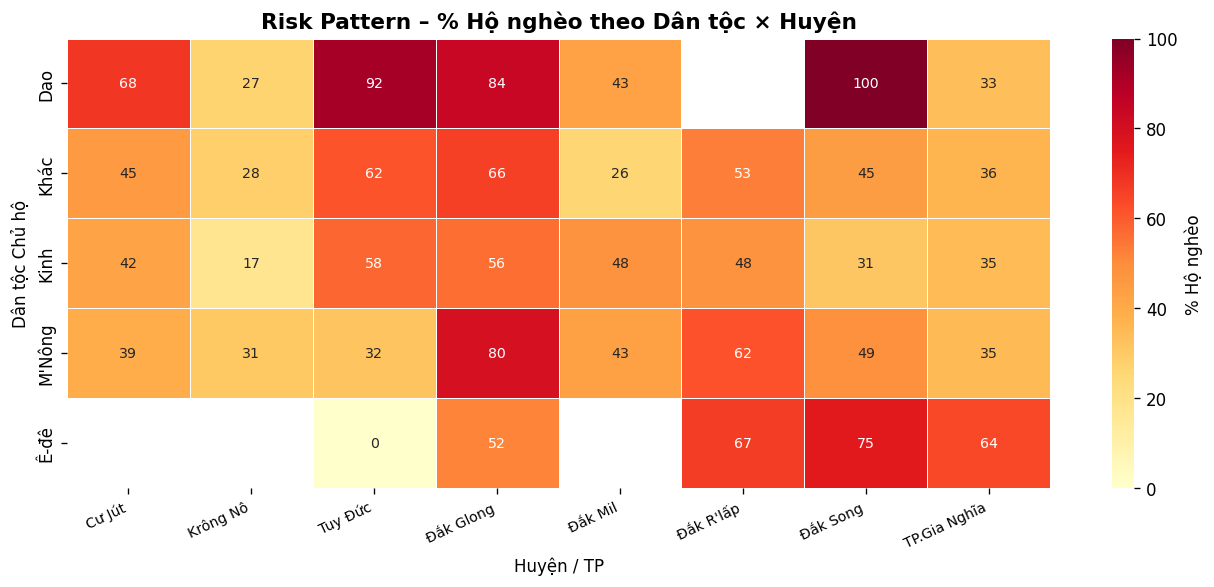

In [32]:
# ── Biểu đồ: Heatmap tương tác ──
fig, ax = plt.subplots(figsize=(11, 5))
sns.heatmap(ct_cross, cmap="YlOrRd", annot=True, fmt=".0f",
            annot_kws={"size": 8.5}, linewidths=0.4,
            cbar_kws={"label":"% Hộ nghèo"},
            ax=ax, vmin=0, vmax=100)
ax.set_title("Risk Pattern – % Hộ nghèo theo Dân tộc × Huyện", fontweight="bold")
ax.set_xlabel("Huyện / TP"); ax.set_ylabel("Dân tộc Chủ hộ")
ax.set_xticklabels(ax.get_xticklabels(), rotation=25, ha="right", fontsize=8.5)
plt.tight_layout(); plt.show()

**Nhận xét:**
- Tỉ lệ hộ nghèo khác biệt rõ theo tổ hợp `DAN_TOC_GRP × HUYEN`.
- Nhóm Dao có tỉ lệ nghèo rất cao ở một số huyện, đặc biệt tại Tuy Đức và Đắk Glong. Các ô có tỷ lệ 100% nhưng số quan sát nhỏ cần được diễn giải thận trọng.
- Krông Nô có tỷ lệ nghèo quan sát thấp hơn ở nhiều nhóm dân tộc, nhưng không nên gọi ngay là “điểm sáng” theo nghĩa nguyên nhân nếu chưa phân tích thêm về sinh kế, hạ tầng, chính sách và cấu trúc dân cư.
- Nhóm Ê-đê biến động mạnh theo huyện; cần xem đồng thời tỷ lệ và số quan sát trước khi rút kết luận.
- Một số ô trống cho thấy không có dữ liệu hoặc mẫu quá nhỏ.

**Insight:**
- Nghèo không chỉ liên quan đến dân tộc hoặc huyện riêng lẻ, mà thể hiện rõ ở tổ hợp dân tộc × địa bàn.
- Các tổ hợp vừa có tỷ lệ nghèo cao vừa có số quan sát đủ lớn nên được ưu tiên phân tích sâu hơn.
- Các tổ hợp có tỷ lệ cao nhưng N nhỏ chỉ nên xem là tín hiệu gợi ý, không đủ cơ sở để kết luận chính sách.
- Đây là phân tích mẫu hình rủi ro, chưa phải root cause. Để giải thích “vì sao”, cần thêm biến về xã, sinh kế, học vấn, nghề nghiệp, hạ tầng, tiếp cận dịch vụ và chính sách.


#### Cấu trúc hộ (nhân khẩu, tỉ lệ lao động, tuổi chủ hộ) khác nhau thế nào giữa các dân tộc, và đây có phải cơ chế giải thích cho khoảng cách nghèo không?

In [33]:
# ── Số liệu ──
struct_dt = (df.groupby("DAN_TOC_GRP")
               .agg(TB_NHAN_KHAU      = ("NHAN_KHAU",      "mean"),
                    TB_LAO_DONG       = ("TY_LE_LAO_DONG",  "mean"),
                    TB_PHU_THUOC      = ("TY_LE_PHU_THUOC", "mean"),
                    TB_TUOI_CHU_HO    = ("TUOI_CHU_HO",     "mean"),
                    TY_LE_NGHEO       = ("Y",               "mean"))
               .round(2))
struct_dt["TY_LE_NGHEO"] = (struct_dt["TY_LE_NGHEO"] * 100).round(1)
struct_dt = struct_dt.sort_values("TY_LE_NGHEO", ascending=False)
print("Cấu trúc hộ trung bình theo Dân tộc:")
print(struct_dt.rename(columns={
    "TB_NHAN_KHAU":"TB Nhân khẩu","TB_LAO_DONG":"TB % Lao động",
    "TB_PHU_THUOC":"TB % Phụ thuộc","TB_TUOI_CHU_HO":"TB Tuổi CĐ",
    "TY_LE_NGHEO":"% Nghèo"}).to_string())


Cấu trúc hộ trung bình theo Dân tộc:
             TB Nhân khẩu  TB % Lao động  TB % Phụ thuộc  TB Tuổi CĐ  % Nghèo
DAN_TOC_GRP                                                                  
Dao                  5.60           0.52            1.18       44.21     82.0
Ê-đê                 3.94           0.52            0.94       48.82     53.0
Khác                 2.88           0.46            0.84       48.15     50.0
M'Nông               4.31           0.52            0.97       47.09     47.0
Kinh                 3.53           0.46            1.02       52.87     43.0


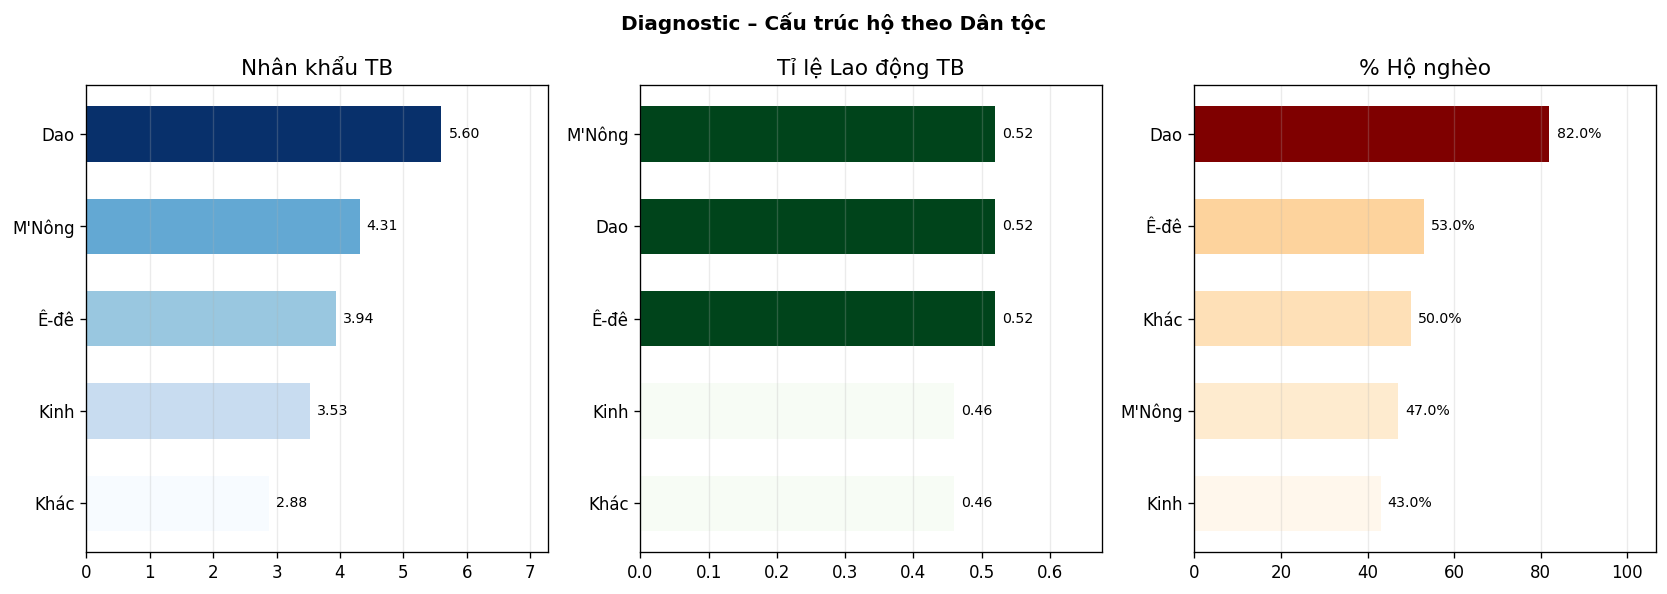

In [34]:
# ── Biểu đồ ──
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.suptitle("Diagnostic – Cấu trúc hộ theo Dân tộc", fontweight="bold")

metrics = [("TB_NHAN_KHAU",   "Nhân khẩu TB",     "Blues"),
           ("TB_LAO_DONG",    "Tỉ lệ Lao động TB","Greens"),
           ("TY_LE_NGHEO",    "% Hộ nghèo",        "OrRd")]

for ax, (col, title, cmap) in zip(axes, metrics):
    data = struct_dt[col].sort_values(ascending=True)
    norm = plt.Normalize(data.min(), data.max())
    colors_ = plt.cm.get_cmap(cmap)(norm(data.values))
    ax.barh(data.index, data.values, color=colors_, height=0.6, edgecolor="none")
    for i, val in enumerate(data.values):
        ax.text(val + data.max()*0.02, i, f"{val:.2f}" if col!="TY_LE_NGHEO" else f"{val:.1f}%",
                va="center", fontsize=8.5)
    ax.set_title(title); ax.grid(axis="x", alpha=0.25)
    ax.set_xlim(0, data.max()*1.3)

plt.tight_layout(); plt.show()


**Nhận xét:**
- Nhóm Dao có nhân khẩu trung bình cao nhất: 5.6 người/hộ.
- Dao, Ê-đê, M’Nông có tỉ lệ lao động TB tương đương nhau, khoảng 0.52.
- Dù tỉ lệ lao động không thấp, nhóm Dao vẫn có % hộ nghèo cao nhất: 82%.
- Nhóm Kinh có nhân khẩu thấp hơn và % hộ nghèo thấp hơn: 43%.

**Insight:**
- Rủi ro nghèo của nhóm Dao có thể không chỉ đến từ thiếu lao động, mà còn liên quan đến quy mô hộ lớn, địa bàn cư trú hoặc điều kiện tiếp cận nguồn lực.
- Nhân khẩu cao + % nghèo cao ở nhóm Dao gợi ý khả năng tồn tại áp lực phụ thuộc/chi tiêu trong hộ.
- Tỉ lệ lao động gần giống nhau giữa Dao, Ê-đê, M’Nông nhưng % nghèo khác nhau → cần phân tích thêm theo huyện/xã để tìm nguyên nhân sâu hơn.

#### Độ lệch tuổi trong hộ (DO_LECH_TUOI) có phân phối khác nhau có ý nghĩa thống kê giữa Hộ nghèo và Hộ cận nghèo không?

In [35]:
# ── Số liệu ──
grp_n = df[df["Y"]==1]["DO_LECH_TUOI"].dropna()
grp_c = df[df["Y"]==0]["DO_LECH_TUOI"].dropna()

u_stat, p_mw = mannwhitneyu(grp_n, grp_c, alternative="two-sided")
n1, n2 = len(grp_n), len(grp_c)

# Effect size r = Z / sqrt(N)
from scipy.stats import norm as scipy_norm
z_mw = scipy_norm.ppf(1 - p_mw/2)
r_eff = z_mw / np.sqrt(n1 + n2)

print("Mann–Whitney U Test: DO_LECH_TUOI – Hộ nghèo vs Hộ cận nghèo")
print(f"  n Hộ nghèo    : {n1:,}")
print(f"  n Hộ cận nghèo: {n2:,}")
print(f"  U statistic   : {u_stat:,.0f}")
print(f"  p-value       : {p_mw:.4e}")
print(f"  Effect size r : {r_eff:.4f}")
sig = "***" if p_mw<0.001 else ("**" if p_mw<0.01 else ("*" if p_mw<0.05 else "ns"))
print(f"  Ý nghĩa       : {sig}")
print()
print("Thống kê mô tả DO_LECH_TUOI:")
desc = pd.DataFrame({
    "Hộ nghèo":     grp_n.describe(),
    "Hộ cận nghèo": grp_c.describe()
}).round(2)
desc.index.name = "Chỉ tiêu"
display(desc)


Mann–Whitney U Test: DO_LECH_TUOI – Hộ nghèo vs Hộ cận nghèo
  n Hộ nghèo    : 13,962
  n Hộ cận nghèo: 12,581
  U statistic   : 84,120,416
  p-value       : 2.2404e-09
  Effect size r : 0.0367
  Ý nghĩa       : ***

Thống kê mô tả DO_LECH_TUOI:


,Hộ nghèo,Hộ cận nghèo
Chỉ tiêu,,
count,13962.00,12581.00
mean,25.17,26.40
std,20.08,19.11
min,0.00,0.00
25%,2.00,5.00
50%,27.00,28.00
75%,37.00,37.00
max,103.00,102.00


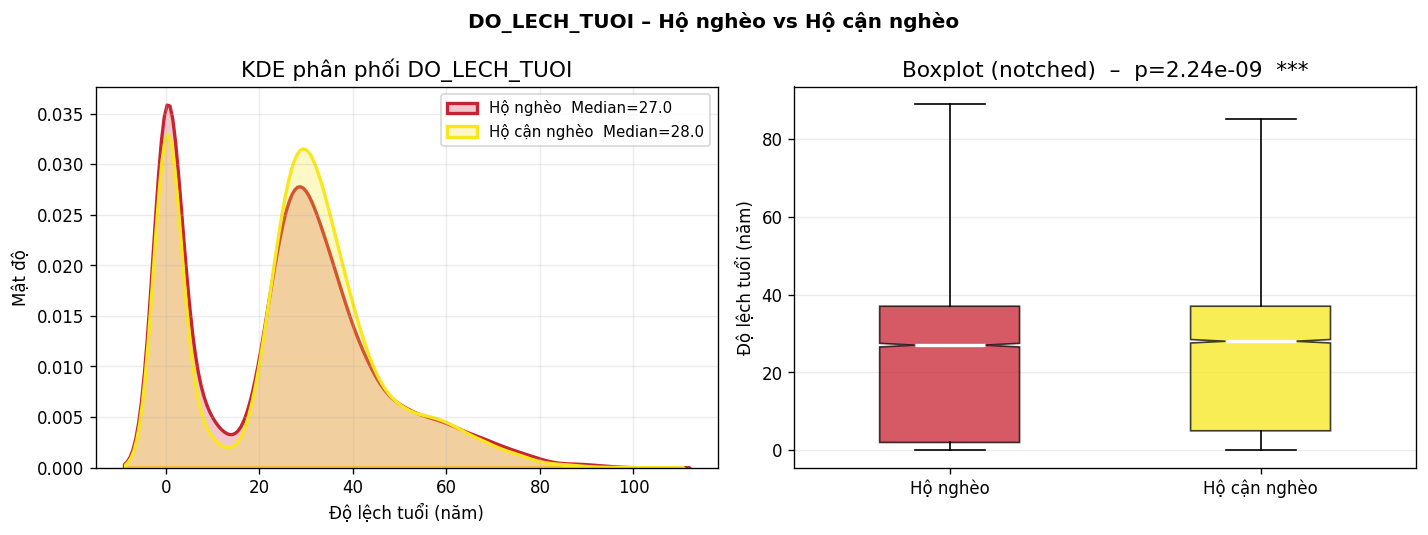

In [36]:
# ── Biểu đồ ──
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
fig.suptitle("DO_LECH_TUOI – Hộ nghèo vs Hộ cận nghèo", fontweight="bold")

# KDE
ax = axes[0]
for vals, label, c in [(grp_n,"Hộ nghèo",CLR["ngheo"]),
                        (grp_c,"Hộ cận nghèo",CLR["can"])]:
    sns.kdeplot(vals, ax=ax, fill=True, alpha=0.25, lw=2, color=c,
                label=f"{label}  Median={vals.median():.1f}")
ax.set_xlabel("Độ lệch tuổi (năm)")
ax.set_ylabel("Mật độ")
ax.set_title("KDE phân phối DO_LECH_TUOI")
ax.legend(fontsize=9); ax.grid(alpha=0.25)

# Boxplot
ax2 = axes[1]
data_box = [grp_n.values, grp_c.values]
bp = ax2.boxplot(data_box, patch_artist=True, notch=True,
                 widths=0.45, showfliers=False)
for patch, c in zip(bp["boxes"], [CLR["ngheo"], CLR["can"]]):
    patch.set_facecolor(c); patch.set_alpha(0.75)
for med in bp["medians"]:
    med.set_color("white"); med.set_linewidth(2)
ax2.set_xticks([1,2])
ax2.set_xticklabels(["Hộ nghèo","Hộ cận nghèo"])
ax2.set_ylabel("Độ lệch tuổi (năm)")
ax2.set_title(f"Boxplot (notched)  –  p={p_mw:.2e}  {sig}")
ax2.grid(axis="y", alpha=0.25)

plt.tight_layout(); plt.show()


**Nhận xét:**
- Phân phối `DO_LECH_TUOI` của hai nhóm khá giống nhau.
- Chênh lệch trung vị/trung bình giữa hộ nghèo và hộ cận nghèo nhỏ.
- Kiểm định có thể cho p-value nhỏ do cỡ mẫu lớn, nhưng effect size thấp cho thấy khác biệt thực tế hạn chế.
- Cả hai nhóm đều có nhiều hộ có độ lệch tuổi cao, phản ánh cấu trúc hộ nhiều thế hệ.

**Insight:**
- Độ lệch tuổi trong hộ không phải yếu tố phân biệt mạnh giữa hộ nghèo và hộ cận nghèo.
- Dù kiểm định có ý nghĩa thống kê, cần ưu tiên đọc effect size để tránh diễn giải quá mức.
- Biến này phù hợp làm biến bổ trợ mô tả cấu trúc hộ, nhưng không nên xem là nguyên nhân chính của nghèo.


In [37]:
OUTPUT_FILE = ROOT / "data" / "model" / "diagnostic_results.xlsx"

with pd.ExcelWriter(
    OUTPUT_FILE,
    engine="openpyxl"
) as writer:

    # 3.1 Kiểm định liên hệ thống kê
    cramers_df.to_excel(
        writer,
        sheet_name="CramersV",
        index=False
    )

    ct_dt.to_excel(
        writer,
        sheet_name="Ethnicity_Poverty"
    )

    ct_tuoi.to_excel(
        writer,
        sheet_name="AgeGroup_Poverty"
    )

    # 3.2 Logistic Regression
    coef_a.to_excel(
        writer,
        sheet_name="Logistic_Model_A"
    )

    or_df.to_excel(
        writer,
        sheet_name="Odds_Ratio"
    )

    coef_b.to_excel(
        writer,
        sheet_name="Logistic_Model_B"
    )

    cmp.to_excel(
        writer,
        sheet_name="Model_Comparison",
        index=False
    )

    # 3.3 Risk Pattern / Diagnostic Analysis
    ct_cross.to_excel(
        writer,
        sheet_name="Ethnicity_Huyen"
    )

    struct_dt.to_excel(
        writer,
        sheet_name="Household_Structure"
    )

    desc.to_excel(
        writer,
        sheet_name="AgeGap_Test",
        index=True
    )

    model_b_check.to_excel(
        writer,
        sheet_name="Model_B_Check",
        index=False
    )

    incremental_numeric.to_excel(
        writer, 
        sheet_name="Numeric_Incremental", 
        index=False
    )

    factor_ranking.to_excel(
        writer,
        sheet_name="Factor_Ranking",
        index=False
    )

print("Đã xuất thành công diagnostic_results.xlsx")
print(f"Vị trí: {OUTPUT_FILE}")

Đã xuất thành công diagnostic_results.xlsx
Vị trí: C:\NguyenHoangThanhTam\data\model\diagnostic_results.xlsx


In [38]:
quality_summary = pd.DataFrame({
    "Chi_tieu": [
        "Tong_nhan_khau",
        "Thieu_NGAY_SINH",
        "Chu_ho_thieu_NGAY_SINH",
        "Ban_ghi_trung_thanh_vien",
        "Ban_ghi_trung_cap_ho",
        "Loi_Serial_Excel",
        "Loi_Nam_sinh_tuong_lai"
    ],
    "Gia_tri": [
        len(df_raw),
        df_raw["LOI_MISSING"].sum(),
        len(n_miss_chuho),
        len(dup_member),
        len(dup_ho),
        len(serial),
        len(tuonglai)
    ]
})

In [39]:
miss_huyen_export = miss_huyen.reset_index()
err_sum_export = err_sum.reset_index()

In [40]:
QUALITY_FILE = (
QUALITY_FILE = ROOT / "data" / "review" / "quality_review.xlsx"
)

with pd.ExcelWriter(
    QUALITY_FILE,
    engine="openpyxl"
) as writer:

    quality_summary.to_excel(
        writer,
        sheet_name="Data_Quality",
        index=False
    )

    miss_huyen_export.to_excel(
        writer,
        sheet_name="Missing_DOB_By_Huyen",
        index=False
    )

    err_sum_export.to_excel(
        writer,
        sheet_name="Error_By_Huyen",
        index=False
    )

print("Đã xuất quality_review.xlsx")
print(f"Vị trí: {QUALITY_FILE}")

Đã xuất quality_review.xlsx
Vị trí: C:\NguyenHoangThanhTam\data\review\quality_review.xlsx


##### **Nhận xét:**
- Diagnostic hiện đã đủ để chuyển sang Predictive/Segmentation. Các kết quả cho thấy địa bàn và dân tộc là hai trục phân hóa chính của tình trạng nghèo/cận nghèo; nhóm biến numeric như nhân khẩu, tỉ lệ lao động và cơ cấu tuổi có đóng góp bổ sung nhưng mức cải thiện nhỏ. Tuy nhiên, phân tích hiện tại vẫn dựa trên dữ liệu cắt ngang và thiếu các biến cơ chế như thu nhập, nghề nghiệp, học vấn, tài sản, đất sản xuất, tiếp cận dịch vụ. Vì vậy, các kết quả nên được xem là nhận diện mẫu hình rủi ro và giả thuyết phân tích, không phải kết luận nhân quả.